
# Supervised Learning for Plant Leaf Disease Classification

## 1. Project Objective

This notebook investigates classical supervised machine learning approaches for plant leaf disease classification.

Histogram of Oriented Gradients (HOG) is used for handcrafted feature extraction. Three classifiers are compared:

- Support Vector Machine (SVM)
- Random Forest
- LightGBM

The objective is to compare their classification performance, computational cost, and ability to distinguish between 19 plant leaf disease classes.

## 2. Dataset

- Total images: 35,181
- Number of classes: 19
- Training images: 24,630
- Validation images: 5,278
- Test images: 5,273

Dataset location:

`C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced`

## 3. Experimental Protocol

- All training images will be used to fit the classifiers.
- All validation images will be used for model comparison and hyperparameter tuning.
- The test set will remain untouched until final evaluation.
- All three classifiers will use the same HOG feature representation and consistent preprocessing.
- Extracted features may be cached to avoid unnecessary repeated computation.
- The selected model configurations will be evaluated on the complete test set.

## 4. Evaluation Metrics

The classifiers will be evaluated using:

- Accuracy
- Precision
- Recall
- Macro-F1 score
- Confusion matrix
- Training time
- Inference time

Macro-F1 will be considered alongside accuracy to assess performance across all classes.

## 5. Expected Outcome

The experiments will establish a classical machine learning baseline for plant leaf disease classification. The results will support comparison with subsequent unsupervised learning, deep learning, and foundation model approaches.


In [ ]:
# Import libraries for image processing, feature extraction, model training, and evaluation.

import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2



from pathlib import Path
from collections import Counter


from PIL import Image, ImageFile
from skimage.feature import hog
from skimage.feature import local_binary_pattern


from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from sklearn.utils.class_weight import compute_class_weight

# Configure image handling and reproducibility.
ImageFile.LOAD_TRUNCATED_IMAGES = False
RANDOM_STATE = 42

print("All required libraries imported successfully.")


All required libraries imported successfully.



## 2. Dataset Configuration

Define the dataset location and verify the training, validation, and test directories before processing images.


In [2]:
# Configure the dataset directories and verify the expected splits.

DATASET_DIR = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")

train_dir = DATASET_DIR / "train"
valid_dir = DATASET_DIR / "valid"
test_dir = DATASET_DIR / "test"

for split, path in {
    "Training": train_dir,
    "Validation": valid_dir,
    "Test": test_dir,
}.items():
    print(f"{split:12}: {path} | Exists: {path.is_dir()}")

assert all(p.is_dir() for p in [train_dir, valid_dir, test_dir]), (
    "Dataset path or split directory is missing. Check DATASET_DIR."
)


Training    : C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\train | Exists: True
Validation  : C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\valid | Exists: True
Test        : C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\test | Exists: True



## 3. Class Distribution

Count the images in each class across the training, validation, and test splits. This verifies class coverage and reveals potential class imbalance.


In [21]:
# Count images per class and summarize each dataset split.

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(split_dir):
    return {
        folder.name: sum(
            1 for file in folder.rglob("*")
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )
        for folder in sorted(split_dir.iterdir())
        if folder.is_dir()
    }

counts = {
    "Train": count_images(train_dir),
    "Validation": count_images(valid_dir),
    "Test": count_images(test_dir),
}

class_counts = pd.DataFrame(counts).fillna(0).astype(int)
display(class_counts)

print("\nImage totals:")
display(class_counts.sum().rename("Images").to_frame().T)


,Train,Validation,Test
Groundnut_early_leaf_spot,909,185,166
Groundnut_early_rust,742,145,179
Groundnut_healthy_leaf,1091,260,205
Groundnut_late_leaf_spot,1009,236,236
Groundnut_nutrition_deficiency,924,211,197
Groundnut_rust,985,191,217
potato_early,1257,277,261
potato_healthy,504,101,127
potato_late,1269,280,288
Tomato___Bacterial_spot,1464,346,314



Image totals:


,Train,Validation,Test
Images,24630,5278,5273


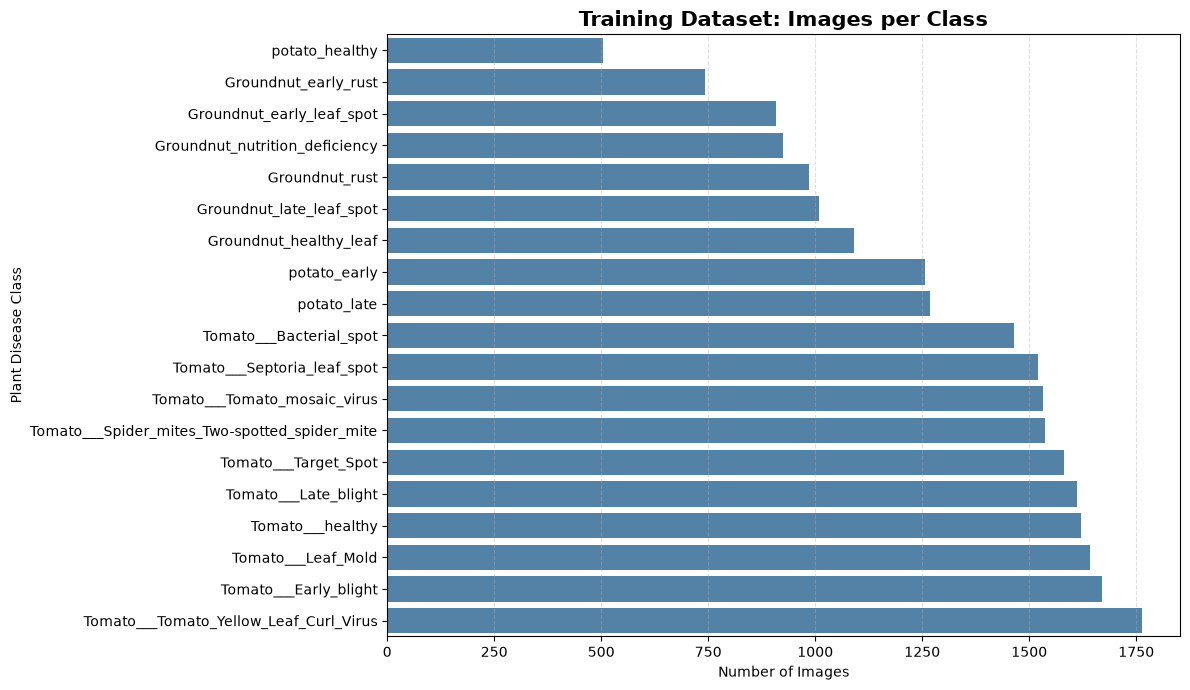

In [22]:
# Visualize the number of training images in each disease class.

plt.figure(figsize=(12, 7))

train_counts = class_counts["Train"].sort_values()

sns.barplot(
    x=train_counts.values,
    y=train_counts.index,
    color="steelblue"
)

plt.title("Training Dataset: Images per Class", fontsize=15, weight="bold")
plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()



## 4. Visual Inspection of Plant Leaf Images

Display representative training images from different classes to observe variations in leaf appearance, disease symptoms, and image characteristics.


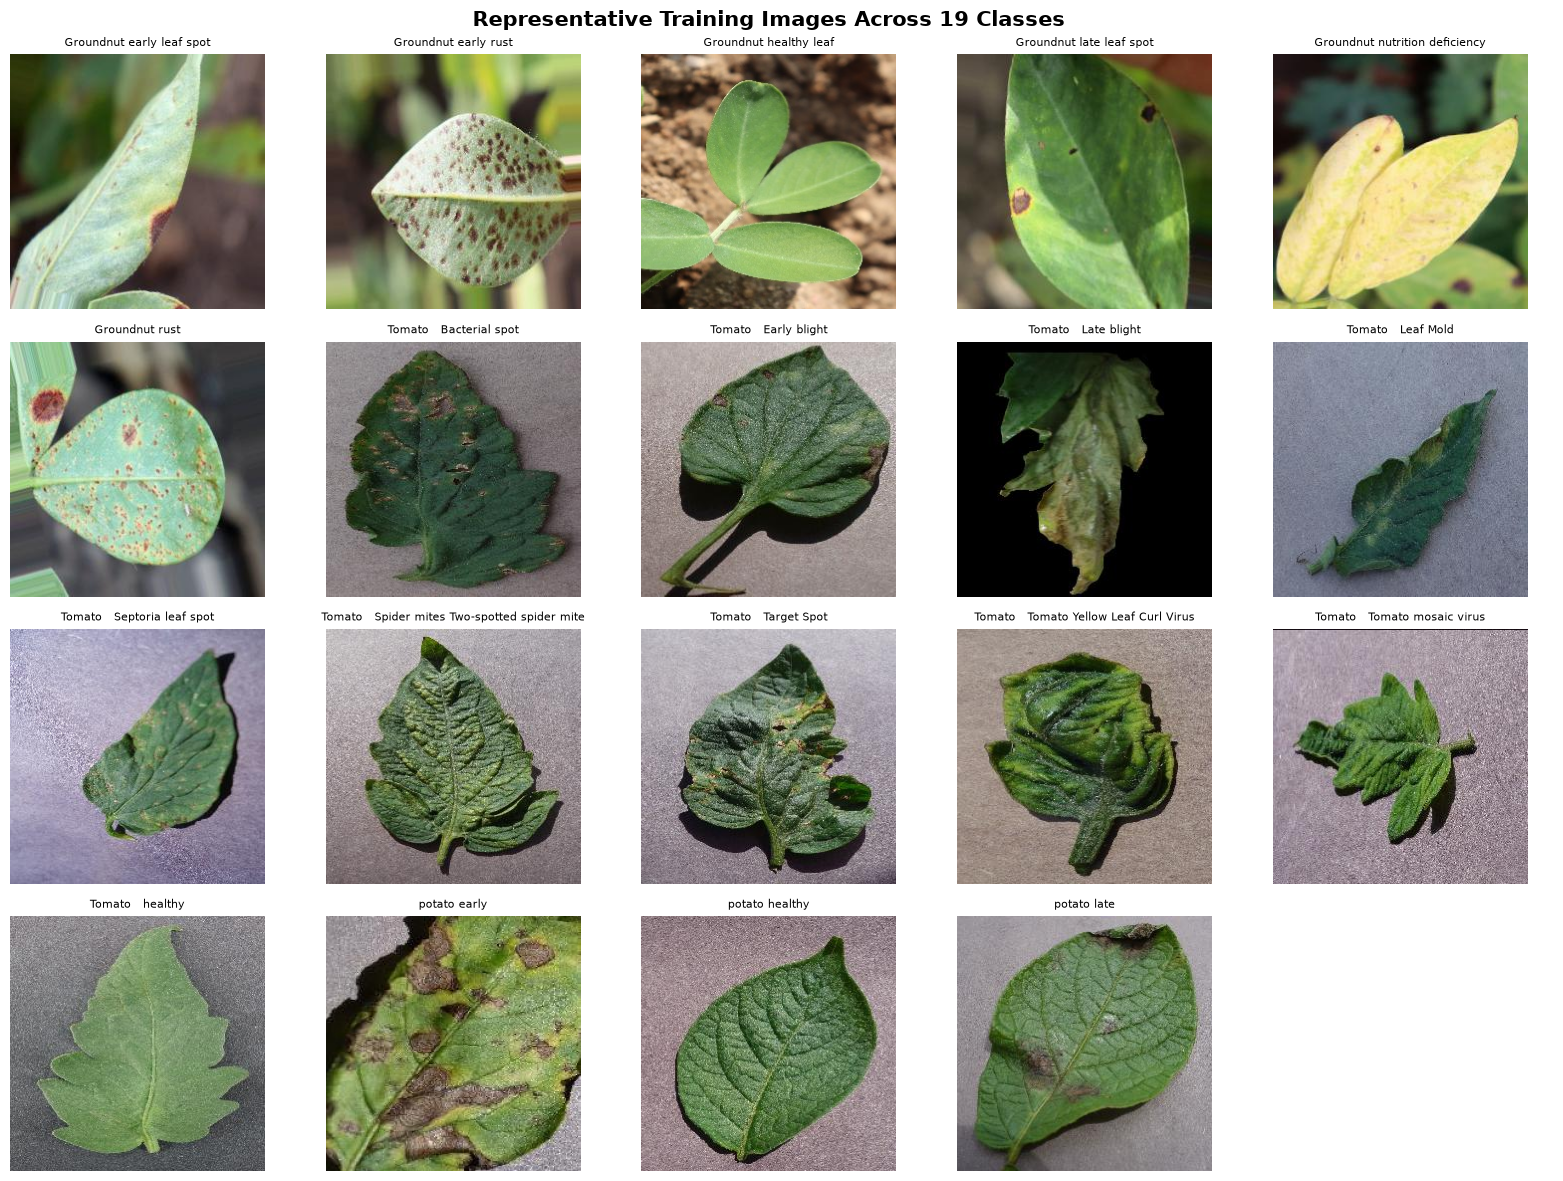

In [23]:
# Display one representative training image from each plant disease class.

class_names = sorted([p.name for p in train_dir.iterdir() if p.is_dir()])

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
axes = axes.flatten()

for ax, class_name in zip(axes, class_names):
    image_path = next(
        p for p in (train_dir / class_name).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name.replace("_", " "), fontsize=8)
    ax.axis("off")

for ax in axes[len(class_names):]:
    ax.axis("off")

plt.suptitle("Representative Training Images Across 19 Classes",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()



## 5. HOG Feature Extraction

Histogram of Oriented Gradients (HOG) represents image structure through local gradient orientations. Images are resized to a consistent resolution before feature extraction so that all samples produce feature vectors of the same length.


In [24]:
# Configure image dimensions and HOG feature extraction.

IMAGE_SIZE = (128, 128)

HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (8, 8),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "transform_sqrt": True,
    "feature_vector": True,
}

print("Image size:", IMAGE_SIZE)
print("HOG parameters:", HOG_PARAMS)


Image size: (128, 128)
HOG parameters: {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2), 'block_norm': 'L2-Hys', 'transform_sqrt': True, 'feature_vector': True}



## 6. HOG Feature Extraction Function

Convert each RGB image to grayscale, resize it consistently, and extract HOG features using the configuration defined above.


In [25]:
# Convert an image into a fixed-length HOG feature vector.

def extract_hog(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB").resize(IMAGE_SIZE)
        image = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

    return hog(image, **HOG_PARAMS)


In [26]:
# Validate HOG extraction on one training image.

sample_class = sorted(p for p in train_dir.iterdir() if p.is_dir())[0]
sample_image = next(
    p for p in sample_class.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

sample_features = extract_hog(sample_image)

print("Sample class:", sample_class.name)
print("Feature vector shape:", sample_features.shape)
print("Feature values finite:", np.isfinite(sample_features).all())
print("Feature values range:", (sample_features.min(), sample_features.max()))


Sample class: Groundnut_early_leaf_spot
Feature vector shape: (8100,)
Feature values finite: True
Feature values range: (np.float32(0.0), np.float32(0.6191544))


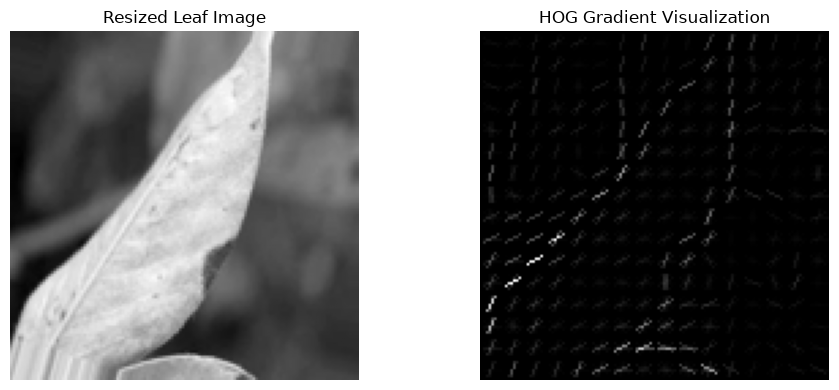

In [27]:
# Compare the original sample image with its HOG representation.

with Image.open(sample_image) as image:
    sample_gray = np.asarray(
        image.convert("L").resize(IMAGE_SIZE), dtype=np.float32
    ) / 255.0

_, sample_hog_image = hog(
    sample_gray,
    **{**HOG_PARAMS, "visualize": True}
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(sample_gray, cmap="gray")
axes[0].set_title("Resized Leaf Image")

axes[1].imshow(sample_hog_image, cmap="gray")
axes[1].set_title("HOG Gradient Visualization")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



## 7. Full-Dataset Feature Extraction

Store extracted HOG features locally to avoid repeating image processing across notebook sessions.


In [28]:

# Define cache locations for training and validation features.

CACHE_DIR = Path("..") / "data" / "hog_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

for split in ["train", "valid"]:
    print(f"{split}: {CACHE_DIR / f'{split}_features.npy'}")


train: ..\data\hog_cache\train_features.npy
valid: ..\data\hog_cache\valid_features.npy


In [29]:
# Extract HOG features for every image in a split and cache features with labels.

def extract_split_features(split_dir, split_name):
    feature_file = CACHE_DIR / f"{split_name}_features.npy"
    label_file = CACHE_DIR / f"{split_name}_labels.npy"

    if feature_file.exists() and label_file.exists():
        print(f"Loading cached {split_name} features...")
        return np.load(feature_file), np.load(label_file, allow_pickle=True)

    image_paths = sorted(
        p for p in split_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    features, labels = [], []

    for i, path in enumerate(image_paths, start=1):
        features.append(extract_hog(path))
        labels.append(path.parent.name)

        if i % 500 == 0 or i == len(image_paths):
            print(f"{split_name}: {i:,}/{len(image_paths):,} images processed")

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels)

    np.save(feature_file, X)
    np.save(label_file, y)

    return X, y


In [30]:
# Extract and cache HOG features for all training and validation images.

X_train, y_train = extract_split_features(train_dir, "train")
X_valid, y_valid = extract_split_features(valid_dir, "valid")

print("\nFeature extraction complete.")
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_valid.shape)
print("Validation labels:", y_valid.shape)


Loading cached train features...
Loading cached valid features...

Feature extraction complete.
Training features: (24630, 8100)
Training labels: (24630,)
Validation features: (5278, 8100)
Validation labels: (5278,)


In [31]:

# Validate feature matrices, labels, and class coverage.

print("Training features finite:", np.isfinite(X_train).all())
print("Validation features finite:", np.isfinite(X_valid).all())

print("Training classes:", len(np.unique(y_train)))
print("Validation classes:", len(np.unique(y_valid)))

print("Training images per label:", len(y_train))
print("Validation images per label:", len(y_valid))

assert X_train.shape == (24630, 8100)
assert X_valid.shape == (5278, 8100)
assert len(np.unique(y_train)) == 19
assert set(np.unique(y_train)) == set(np.unique(y_valid))
assert np.isfinite(X_train).all() and np.isfinite(X_valid).all()

print("\nFeature validation passed.")


Training features finite: True
Validation features finite: True
Training classes: 19
Validation classes: 19
Training images per label: 24630
Validation images per label: 5278

Feature validation passed.


## Train

In [32]:
# Train a linear SVM using the complete HOG training feature matrix.

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=3000
    ))
])

start_time = time.time()
svm_model.fit(X_train, y_train)
svm_training_time = time.time() - start_time

print(f"SVM training completed in {svm_training_time:.2f} seconds.")


: 

: 

In [ ]:
# Reload cached HOG features after the kernel restart.

from pathlib import Path
import numpy as np

CACHE_DIR = Path("..") / "data" / "hog_cache"

X_train = np.load(CACHE_DIR / "train_features.npy", mmap_mode="r")
y_train = np.load(CACHE_DIR / "train_labels.npy", allow_pickle=True)

X_valid = np.load(CACHE_DIR / "valid_features.npy", mmap_mode="r")
y_valid = np.load(CACHE_DIR / "valid_labels.npy", allow_pickle=True)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_valid.shape)
print("Validation labels:", y_valid.shape)


Training features: (24630, 8100)
Training labels: (24630,)
Validation features: (5278, 8100)
Validation labels: (5278,)


In [ ]:
# Train a linear SVM with variance scaling and no centering.

svm_model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        dual=False,
        tol=1e-3,
        random_state=RANDOM_STATE,
        max_iter=3000
    ))
])

start_time = time.time()
svm_model.fit(X_train, y_train)
svm_training_time = time.time() - start_time

print(f"SVM training completed in {svm_training_time:.2f} seconds.")
print("Training samples:", len(y_train))
print("Number of classes:", len(svm_model.classes_))


SVM training completed in 4082.75 seconds.
Training samples: 24630
Number of classes: 19


In [ ]:
# Evaluate the trained Linear SVM on the validation set.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import time

start_time = time.time()

y_valid_pred = svm_model.predict(X_valid)

svm_validation_time = time.time() - start_time

print("SVM Validation Results")
print("-" * 40)
print(f"Validation time: {svm_validation_time:.2f} seconds")
print(f"Accuracy:  {accuracy_score(y_valid, y_valid_pred):.4f}")
print(f"Macro Precision: {precision_score(y_valid, y_valid_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:    {recall_score(y_valid, y_valid_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score:  {f1_score(y_valid, y_valid_pred, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(y_valid, y_valid_pred, zero_division=0))

SVM Validation Results
----------------------------------------
Validation time: 0.58 seconds
Accuracy:  0.4521
Macro Precision: 0.4464
Macro Recall:    0.4427
Macro F1-score:  0.4435

Classification Report:
                                               precision    recall  f1-score   support

                    Groundnut_early_leaf_spot       0.36      0.35      0.36       185
                         Groundnut_early_rust       0.44      0.37      0.40       145
                       Groundnut_healthy_leaf       0.40      0.35      0.37       260
                     Groundnut_late_leaf_spot       0.31      0.25      0.28       236
               Groundnut_nutrition_deficiency       0.50      0.39      0.44       211
                               Groundnut_rust       0.60      0.62      0.61       191
                      Tomato___Bacterial_spot       0.55      0.58      0.56       346
                        Tomato___Early_blight       0.26      0.26      0.26       363
        

In [ ]:
# Inspect the fitted SVM pipeline and its configuration.

print("SVM pipeline:")
print(svm_model)

print("\nClassifier details:")
print("C:", svm_model.named_steps["classifier"].C)
print("Loss:", svm_model.named_steps["classifier"].loss)
print("Dual:", svm_model.named_steps["classifier"].dual)
print("Tolerance:", svm_model.named_steps["classifier"].tol)
print("Iterations:", svm_model.named_steps["classifier"].n_iter_)

SVM pipeline:
Pipeline(steps=[('scaler', StandardScaler(with_mean=False)),
                ('classifier',
                 LinearSVC(class_weight='balanced', dual=False, max_iter=3000,
                           random_state=42, tol=0.001))])

Classifier details:
C: 1.0
Loss: squared_hinge
Dual: False
Tolerance: 0.001
Iterations: 178


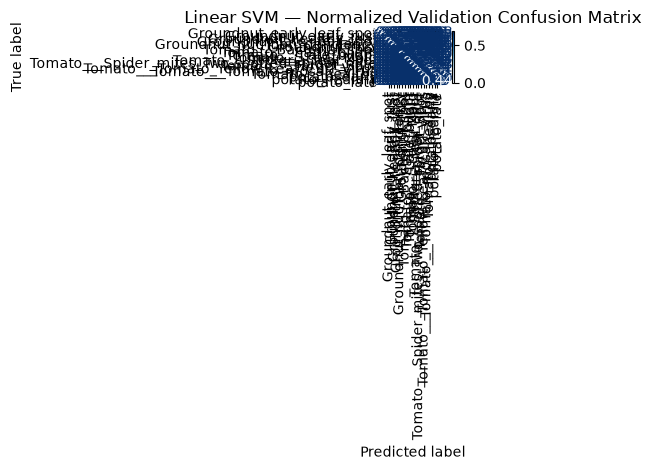

In [ ]:
# Visualize validation-set classification errors.

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_valid_pred,
    xticks_rotation="vertical",
    cmap="Blues",
    normalize="true",
    values_format=".2f"
)

plt.title("Linear SVM — Normalized Validation Confusion Matrix")
plt.tight_layout()
plt.show()

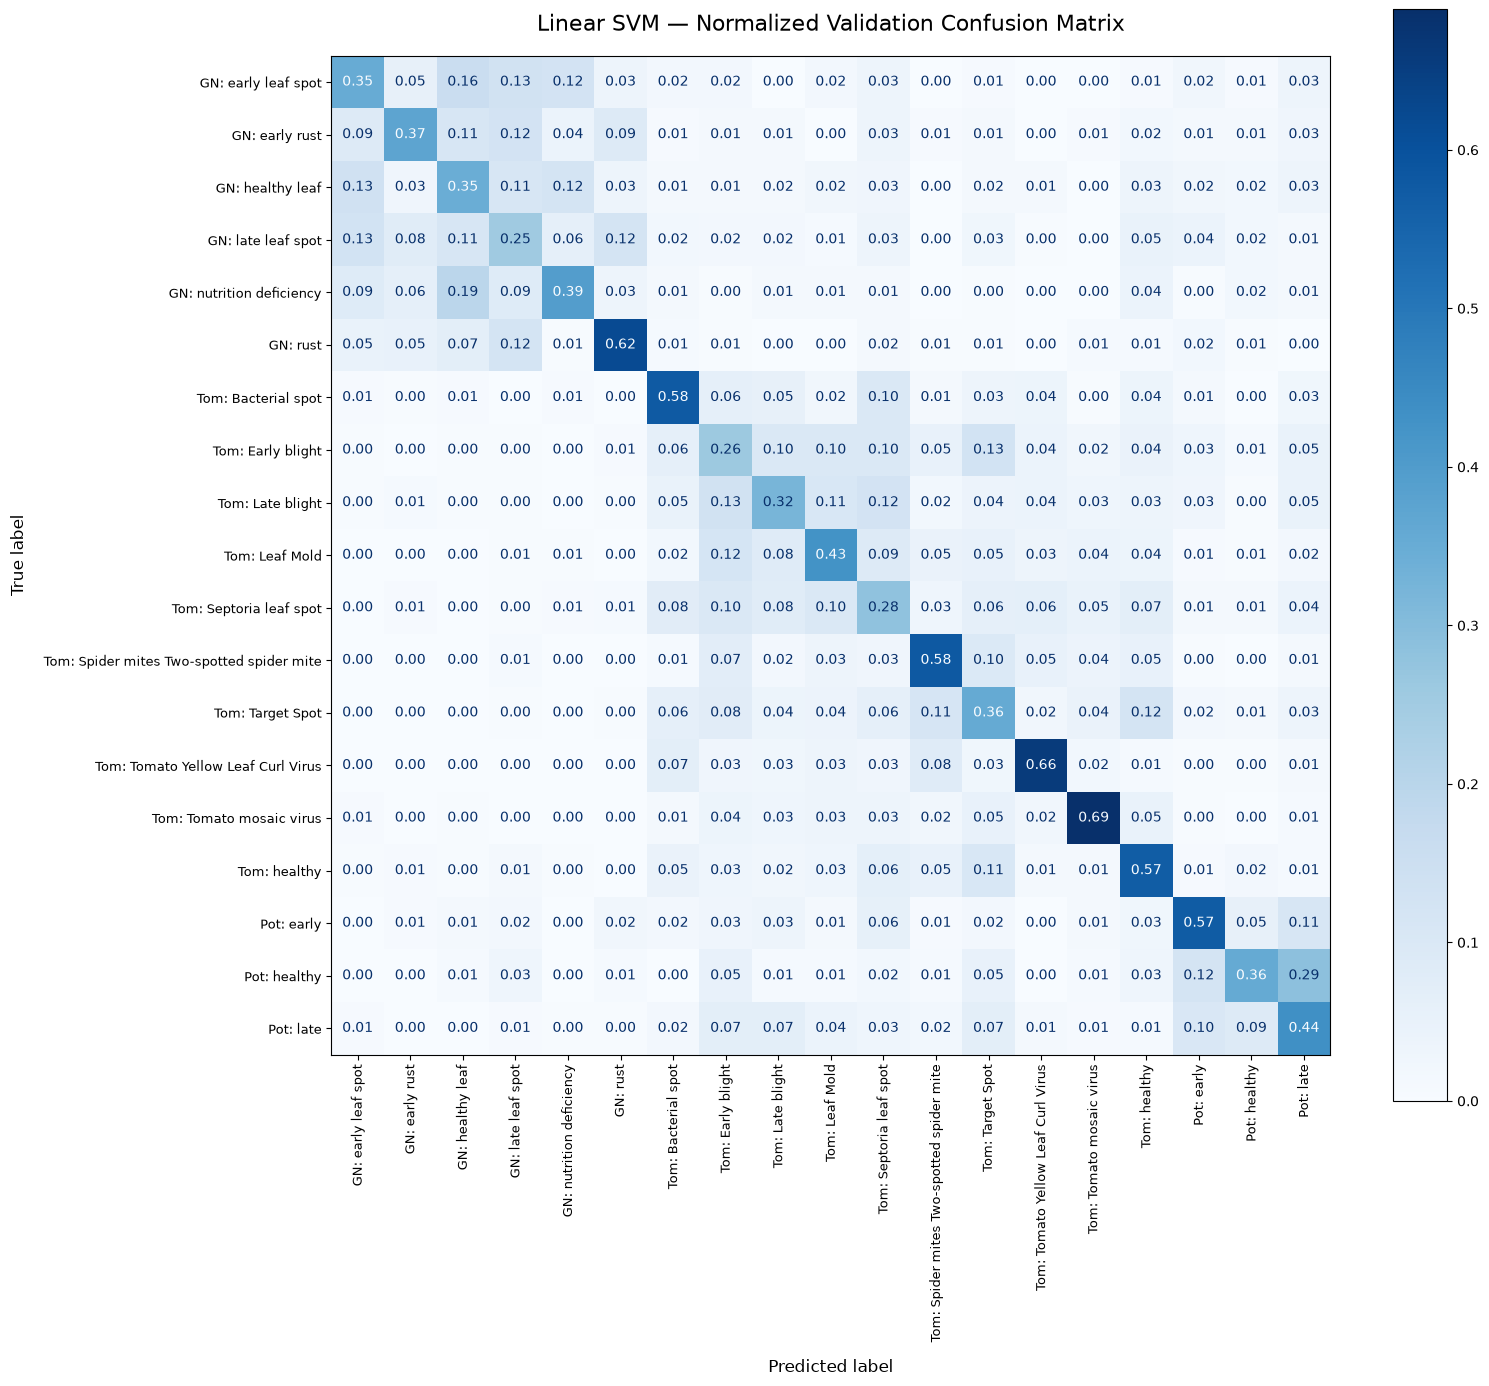

In [ ]:
# Plot a readable normalized confusion matrix for the trained Linear SVM.

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Preserve the existing validation predictions and class order.
class_names = list(svm_model.classes_)

# Calculate row-normalized confusion matrix.
cm = confusion_matrix(
    y_valid,
    y_valid_pred,
    labels=class_names,
    normalize="true"
)

# Shorten labels for better readability without changing class names in the data.
short_names = [
    name.replace("Groundnut_", "GN: ")
        .replace("Tomato___", "Tom: ")
        .replace("potato_", "Pot: ")
        .replace("_", " ")
    for name in class_names
]

# Create a large, square figure.
fig, ax = plt.subplots(figsize=(16, 14))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=short_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=90,
    colorbar=True,
    include_values=True
)

ax.set_title(
    "Linear SVM — Normalized Validation Confusion Matrix",
    fontsize=16,
    pad=18
)
ax.set_xlabel("Predicted label", fontsize=12, labelpad=12)
ax.set_ylabel("True label", fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Save the trained Linear SVM model for future use.

from pathlib import Path
import joblib

MODEL_DIR = Path("..") / "reports" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "linear_svm_hog.joblib"

joblib.dump(svm_model, model_path)

print("SVM model saved successfully.")
print("Location:", model_path.resolve())

SVM model saved successfully.
Location: C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection\reports\models\linear_svm_hog.joblib


## HSV Colour Histogram Feature Extraction

HOG captures edge and gradient patterns but does not preserve the full colour information of the original leaf image. In this step, HSV colour histograms will be extracted from the original colour images to represent their colour distributions. We will first validate the feature dimensions on a single image before processing the full training and validation splits.

In [ ]:
# Define an HSV colour histogram extractor for plant leaf images.

import cv2
import numpy as np
from pathlib import Path

HSV_BINS = (8, 8, 8)

def extract_hsv_histogram(image_path):
    """Extract a normalized HSV colour histogram from one image."""
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    histogram = cv2.calcHist(
        [hsv_image],
        [0, 1, 2],
        None,
        HSV_BINS,
        [0, 180, 0, 256, 0, 256]
    )

    histogram = cv2.normalize(histogram, None).flatten()
    return histogram

print("HSV histogram extractor defined.")
print("Histogram bins:", HSV_BINS)
print("Features per image:", np.prod(HSV_BINS))

HSV histogram extractor defined.
Histogram bins: (8, 8, 8)
Features per image: 512


In [ ]:
# Validate the HSV histogram extractor on one training image.

sample_class_dir = next(
    folder for folder in sorted(train_dir.iterdir())
    if folder.is_dir()
)

sample_image = next(
    path for path in sorted(sample_class_dir.iterdir())
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

sample_hsv = extract_hsv_histogram(sample_image)

print("Sample image:", sample_image.name)
print("HSV feature shape:", sample_hsv.shape)
print("All values finite:", np.isfinite(sample_hsv).all())
print("Feature norm:", np.linalg.norm(sample_hsv))

Sample image: 000001_000001_09083a8bc6544eff84d04024fd252cdb.jpg
HSV feature shape: (512,)
All values finite: True
Feature norm: 1.0


## Full HSV Colour Feature Extraction

Extract normalized HSV colour histograms for every image in the training and validation splits. Cache the feature matrices and labels for reuse in later experiments. The test set will remain untouched.

In [ ]:
# Extract and cache HSV histograms for all training and validation images.

import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

HSV_CACHE_DIR = Path("..") / "data" / "hsv_cache"
HSV_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def extract_split_hsv(split_dir, split_name):
    """Extract HSV histograms and cache features and labels for one split."""
    feature_path = HSV_CACHE_DIR / f"{split_name}_features.npy"
    label_path = HSV_CACHE_DIR / f"{split_name}_labels.npy"

    # Reuse cached features if both files already exist.
    if feature_path.exists() and label_path.exists():
        print(f"Loading cached HSV features for {split_name}...")
        return (
            np.load(feature_path, mmap_mode="r"),
            np.load(label_path, allow_pickle=True)
        )

    features = []
    labels = []

    class_dirs = sorted(
        folder for folder in split_dir.iterdir()
        if folder.is_dir()
    )

    for class_dir in class_dirs:
        image_paths = sorted(
            path for path in class_dir.iterdir()
            if path.is_file()
            and path.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )

        for image_path in tqdm(
            image_paths,
            desc=f"{split_name}: {class_dir.name}",
            leave=False
        ):
            features.append(extract_hsv_histogram(image_path))
            labels.append(class_dir.name)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=str)

    np.save(feature_path, X)
    np.save(label_path, y)

    print(f"{split_name} HSV features: {X.shape}")
    print(f"{split_name} labels: {y.shape}")

    return X, y


X_train_hsv, y_train_hsv = extract_split_hsv(train_dir, "train")
X_valid_hsv, y_valid_hsv = extract_split_hsv(valid_dir, "valid")

print("\nHSV feature extraction complete.")
print("Training:", X_train_hsv.shape, y_train_hsv.shape)
print("Validation:", X_valid_hsv.shape, y_valid_hsv.shape)

c:\Users\KEERTHAN REDDY\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train HSV features: (24630, 512)
train labels: (24630,)


valid HSV features: (5278, 512)
valid labels: (5278,)

HSV feature extraction complete.
Training: (24630, 512) (24630,)
Validation: (5278, 512) (5278,)


In [ ]:
# Define an LBP texture extractor that returns a normalized 10-bin histogram per image.

import cv2
import numpy as np
from skimage.feature import local_binary_pattern

LBP_POINTS = 8
LBP_RADIUS = 1
LBP_METHOD = "uniform"
LBP_BINS = LBP_POINTS + 2  # 10 bins for uniform LBP with 8 neighbours

def extract_lbp_histogram(image_path):
    """Extract a normalized LBP texture histogram from one image."""
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    lbp_image = local_binary_pattern(
        gray,
        P=LBP_POINTS,
        R=LBP_RADIUS,
        method=LBP_METHOD
    )

    histogram, _ = np.histogram(
        lbp_image.ravel(),
        bins=np.arange(-0.5, LBP_BINS + 0.5, 1)
    )

    histogram = histogram.astype(np.float32)
    histogram /= max(histogram.sum(), 1)

    return histogram


In [ ]:
# Verify the LBP extractor on one training image before processing the full dataset.

sample_class = sorted(
    folder for folder in train_dir.iterdir() if folder.is_dir()
)[0]

sample_image = next(
    path for path in sample_class.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

sample_lbp = extract_lbp_histogram(sample_image)

print("Sample image:", sample_image.name)
print("LBP feature shape:", sample_lbp.shape)
print("All values finite:", np.isfinite(sample_lbp).all())
print("Histogram sum:", sample_lbp.sum())


Sample image: 000001_000001_09083a8bc6544eff84d04024fd252cdb.jpg
LBP feature shape: (10,)
All values finite: True
Histogram sum: 1.0


In [ ]:
# Extract and cache LBP texture features for the complete training and validation splits.

from pathlib import Path
import numpy as np
from tqdm.auto import tqdm

LBP_CACHE_DIR = Path("..") / "data" / "lbp_cache"
LBP_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def extract_split_lbp(split_dir, split_name):
    """Extract LBP histograms and labels, or load the existing cache."""
    feature_path = LBP_CACHE_DIR / f"{split_name}_features.npy"
    label_path = LBP_CACHE_DIR / f"{split_name}_labels.npy"

    if feature_path.exists() and label_path.exists():
        print(f"Loading cached LBP features for {split_name}...")
        return (
            np.load(feature_path, mmap_mode="r"),
            np.load(label_path, allow_pickle=True)
        )

    features = []
    labels = []

    class_dirs = sorted(
        folder for folder in split_dir.iterdir()
        if folder.is_dir()
    )

    for class_dir in class_dirs:
        image_paths = sorted(
            path for path in class_dir.iterdir()
            if path.is_file()
            and path.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )

        for image_path in tqdm(
            image_paths,
            desc=f"{split_name}: {class_dir.name}",
            leave=False
        ):
            features.append(extract_lbp_histogram(image_path))
            labels.append(class_dir.name)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=str)

    np.save(feature_path, X)
    np.save(label_path, y)

    print(f"{split_name} LBP features: {X.shape}")
    print(f"{split_name} labels: {y.shape}")

    return X, y


X_train_lbp, y_train_lbp = extract_split_lbp(train_dir, "train")
X_valid_lbp, y_valid_lbp = extract_split_lbp(valid_dir, "valid")

print("\nLBP feature extraction complete.")
print("Training:", X_train_lbp.shape, y_train_lbp.shape)
print("Validation:", X_valid_lbp.shape, y_valid_lbp.shape)


train LBP features: (24630, 10)
train labels: (24630,)


valid LBP features: (5278, 10)
valid labels: (5278,)

LBP feature extraction complete.
Training: (24630, 10) (24630,)
Validation: (5278, 10) (5278,)


In [ ]:
# Identify the feature and label arrays currently available in the notebook.

for name in [
    "X_train", "y_train", "X_valid", "y_valid",
    "X_train_hog", "y_train_hog", "X_valid_hog", "y_valid_hog",
    "X_train_hsv", "y_train_hsv", "X_valid_hsv", "y_valid_hsv",
    "X_train_lbp", "y_train_lbp", "X_valid_lbp", "y_valid_lbp"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape={getattr(value, 'shape', 'not an array')}")


X_train_hsv: shape=(24630, 512)
y_train_hsv: shape=(24630,)
X_valid_hsv: shape=(5278, 512)
y_valid_hsv: shape=(5278,)
X_train_lbp: shape=(24630, 10)
y_train_lbp: shape=(24630,)
X_valid_lbp: shape=(5278, 10)
y_valid_lbp: shape=(5278,)


In [ ]:
# Reload previously cached HOG features and labels without repeating extraction.
HOG_CACHE_DIR = Path("..") / "data" / "hog_cache"

X_train_hog = np.load(
    HOG_CACHE_DIR / "train_features.npy", mmap_mode="r"
)
y_train_hog = np.load(
    HOG_CACHE_DIR / "train_labels.npy", allow_pickle=True
)
X_valid_hog = np.load(
    HOG_CACHE_DIR / "valid_features.npy", mmap_mode="r"
)
y_valid_hog = np.load(
    HOG_CACHE_DIR / "valid_labels.npy", allow_pickle=True
)

print("HOG training:", X_train_hog.shape, y_train_hog.shape)
print("HOG validation:", X_valid_hog.shape, y_valid_hog.shape)


HOG training: (24630, 8100) (24630,)
HOG validation: (5278, 8100) (5278,)


In [ ]:

# Verify label alignment and concatenate HOG, HSV, and LBP features.

assert np.array_equal(y_train_hog, y_train_hsv), "Training HSV labels differ from HOG labels."
assert np.array_equal(y_train_hog, y_train_lbp), "Training LBP labels differ from HOG labels."
assert np.array_equal(y_valid_hog, y_valid_hsv), "Validation HSV labels differ from HOG labels."
assert np.array_equal(y_valid_hog, y_valid_lbp), "Validation LBP labels differ from HOG labels."

X_train_combined = np.concatenate(
    [X_train_hog, X_train_hsv, X_train_lbp], axis=1
)
X_valid_combined = np.concatenate(
    [X_valid_hog, X_valid_hsv, X_valid_lbp], axis=1
)

y_train_combined = y_train_hog
y_valid_combined = y_valid_hog

print("Combined training:", X_train_combined.shape)
print("Combined validation:", X_valid_combined.shape)
print("Training values finite:", np.isfinite(X_train_combined).all())
print("Validation values finite:", np.isfinite(X_valid_combined).all())
print("Label alignment verified.")


Combined training: (24630, 8622)
Combined validation: (5278, 8622)
Training values finite: True
Validation values finite: True
Label alignment verified.


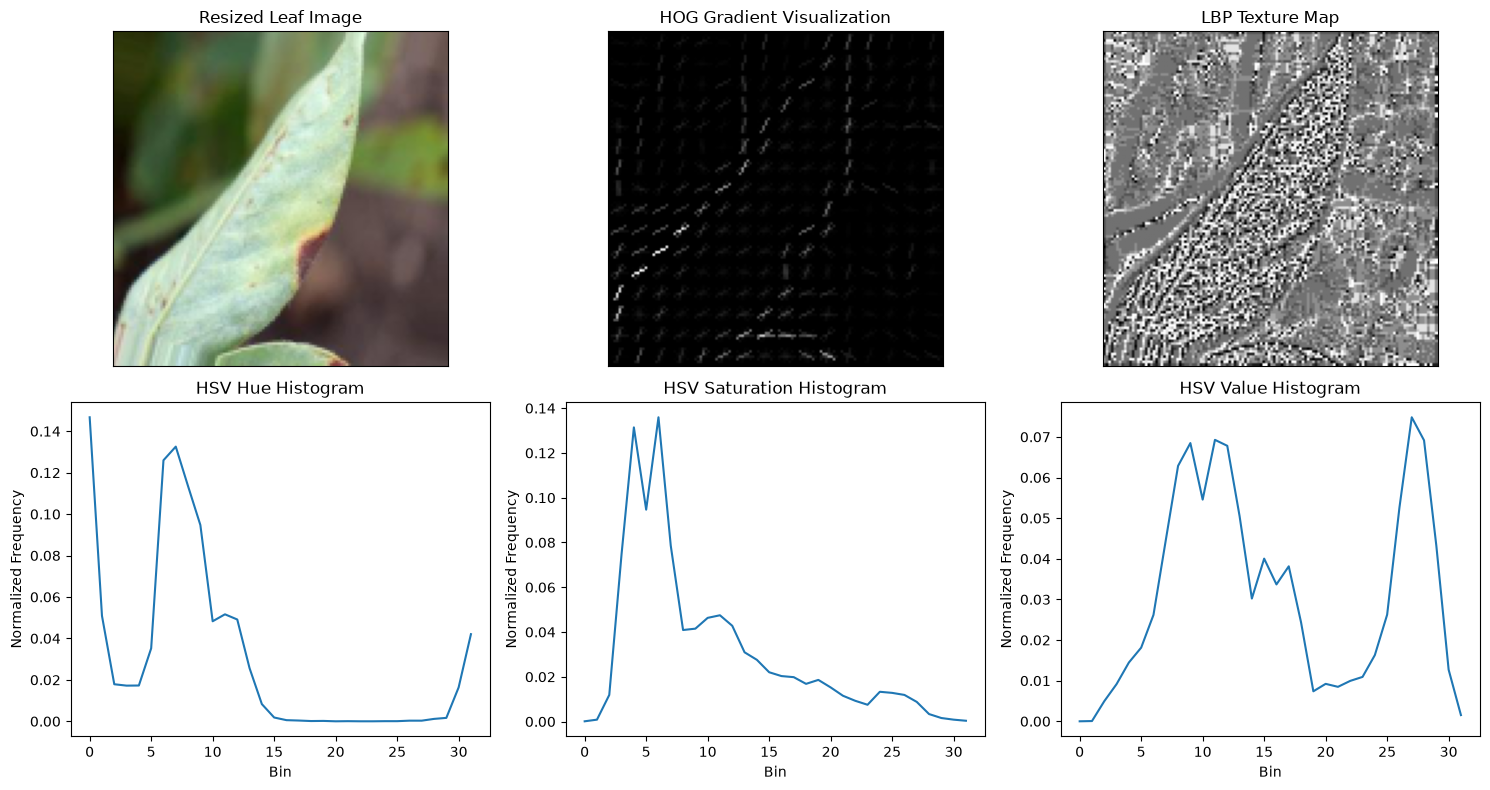

HOG feature length: 8100
HSV combined feature length: 512
LBP feature length: 10


In [11]:

# Visualize HOG gradients, HSV colour distributions, and LBP texture for one leaf image.
# Select one image from the existing training dataset.
sample_class = sorted(
    folder for folder in train_dir.iterdir() if folder.is_dir()
)[0]

sample_image = next(
    path for path in sample_class.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

# Read and prepare the image.
image_bgr = cv2.imread(str(sample_image))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image_resized = cv2.resize(image_rgb, (128, 128))
gray = cv2.cvtColor(image_resized, cv2.COLOR_RGB2GRAY)

# HOG: calculate the feature vector and gradient visualization.
hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    transform_sqrt=True,
    visualize=True,
    feature_vector=True
)

# HSV: calculate separate histograms for hue, saturation, and value.
hsv = cv2.cvtColor(image_resized, cv2.COLOR_RGB2HSV)
hsv_names = ["Hue", "Saturation", "Value"]
hsv_channels = [0, 1, 2]
hsv_ranges = [(0, 180), (0, 256), (0, 256)]

# LBP: create a texture map.
lbp_map = local_binary_pattern(
    gray, P=8, R=1, method="uniform"
)

# Plot the visualizations.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].imshow(image_resized)
axes[0, 0].set_title("Resized Leaf Image")

axes[0, 1].imshow(hog_image, cmap="gray")
axes[0, 1].set_title("HOG Gradient Visualization")

axes[0, 2].imshow(lbp_map, cmap="gray")
axes[0, 2].set_title("LBP Texture Map")

for i, (channel, value_range, name) in enumerate(
    zip(hsv_channels, hsv_ranges, hsv_names)
):
    histogram = cv2.calcHist(
        [hsv], [channel], None, [32], list(value_range)
    )
    histogram = histogram / max(histogram.sum(), 1)

    axes[1, i].plot(histogram.ravel())
    axes[1, i].set_title(f"HSV {name} Histogram")
    axes[1, i].set_xlabel("Bin")
    axes[1, i].set_ylabel("Normalized Frequency")

for ax in axes.flat:
    if ax not in axes[1]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

print("HOG feature length:", len(hog_features))
print("HSV combined feature length:", len(extract_hsv_histogram(sample_image)))
print("LBP feature length:", len(extract_lbp_histogram(sample_image)))


In [ ]:
# Train the model.
combined_svm = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

start_time = time.time()
combined_svm.fit(X_train_combined, y_train_combined)
training_seconds = time.time() - start_time

print(f"Training time: {training_seconds / 60:.2f} minutes")

# Evaluate on validation data only.
start_time = time.time()
y_valid_pred_combined = combined_svm.predict(X_valid_combined)
prediction_seconds = time.time() - start_time

print(f"Prediction time: {prediction_seconds:.2f} seconds")

print("\nCombined HOG + HSV + LBP — Validation Results")
print(f"Accuracy:        {accuracy_score(y_valid_combined, y_valid_pred_combined):.4f}")
print(f"Macro precision: {precision_score(y_valid_combined, y_valid_pred_combined, average='macro', zero_division=0):.4f}")
print(f"Macro recall:    {recall_score(y_valid_combined, y_valid_pred_combined, average='macro', zero_division=0):.4f}")
print(f"Macro F1:        {f1_score(y_valid_combined, y_valid_pred_combined, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_valid_combined,
    y_valid_pred_combined,
    zero_division=0
))

# Save the trained model.
MODEL_DIR = Path("..") / "reports" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "linear_svm_hog_hsv_lbp.joblib"
joblib.dump(combined_svm, model_path)

print("\nModel saved to:", model_path.resolve())

Training time: 23.86 minutes
Prediction time: 0.12 seconds

Combined HOG + HSV + LBP — Validation Results
Accuracy:        0.7664
Macro precision: 0.7688
Macro recall:    0.7668
Macro F1:        0.7673

Classification report:
                                               precision    recall  f1-score   support

                    Groundnut_early_leaf_spot       0.54      0.58      0.56       185
                         Groundnut_early_rust       0.89      0.86      0.87       145
                       Groundnut_healthy_leaf       0.68      0.63      0.65       260
                     Groundnut_late_leaf_spot       0.67      0.62      0.64       236
               Groundnut_nutrition_deficiency       0.81      0.78      0.79       211
                               Groundnut_rust       0.91      0.95      0.93       191
                      Tomato___Bacterial_spot       0.86      0.85      0.86       346
                        Tomato___Early_blight       0.69      0.61      0.65 

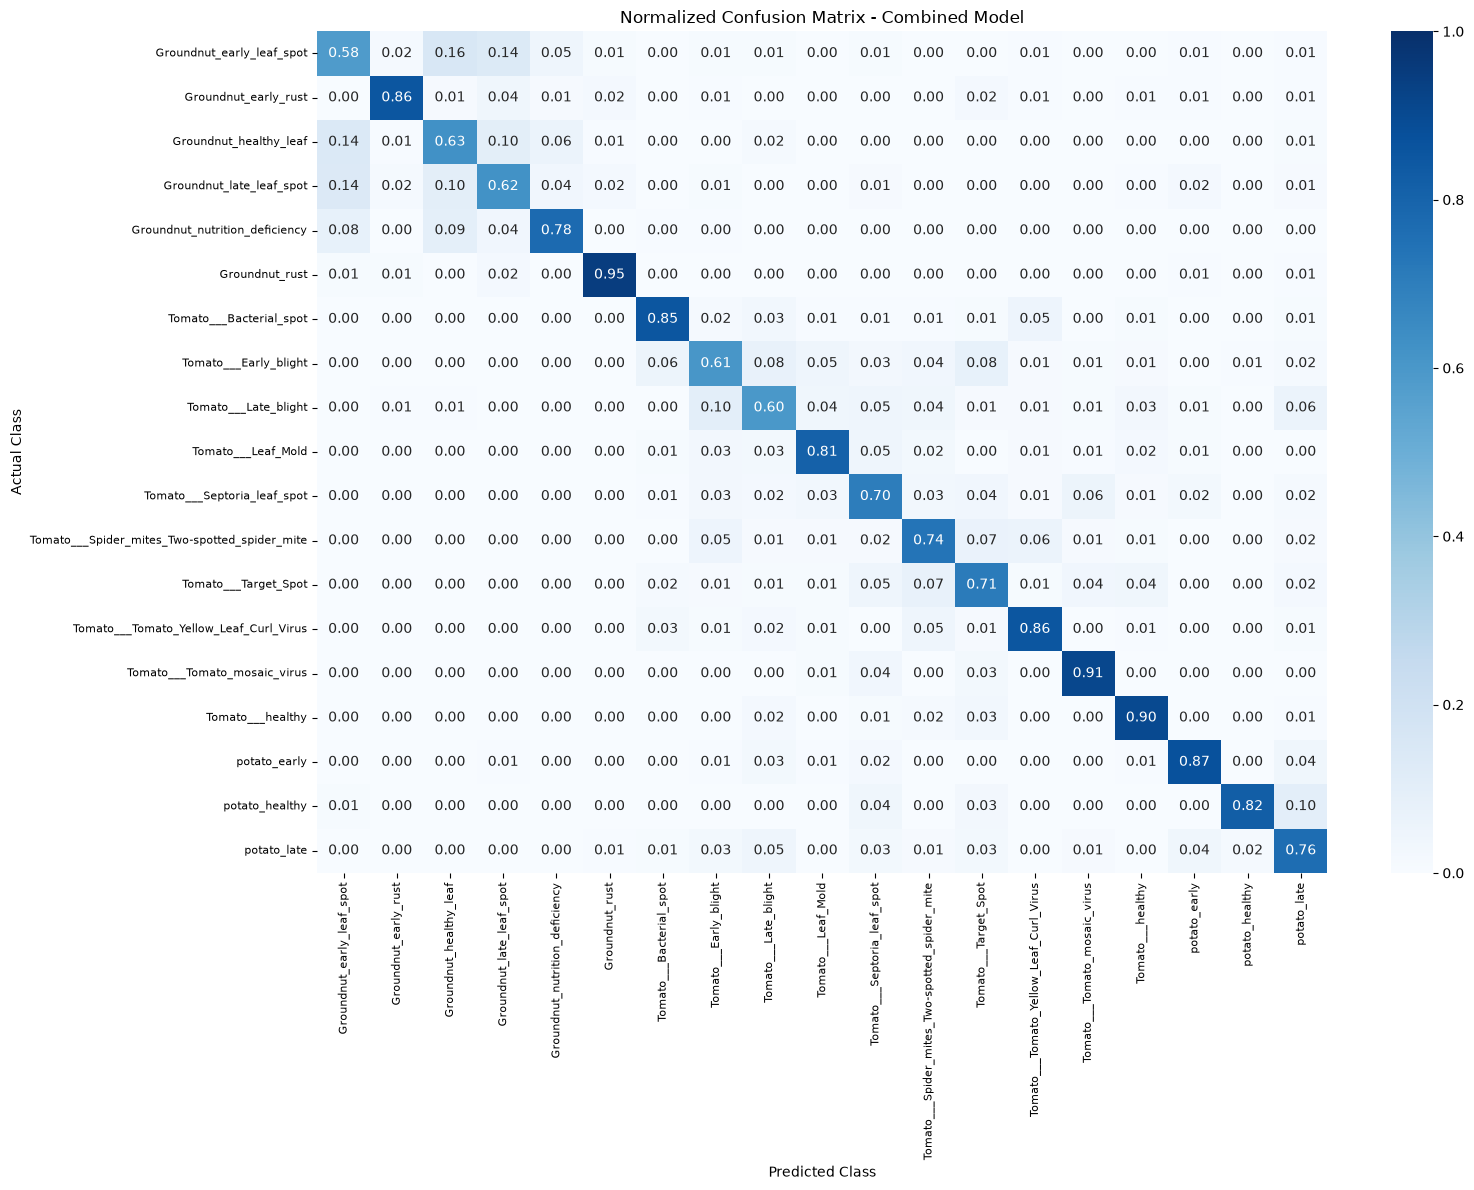

In [17]:
# Plot the normalized confusion matrix to compare class-wise recall.
cm_normalized = confusion_matrix(
    y_valid_combined,
    y_valid_pred_combined,
    labels=class_names,
    normalize="true"
)

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix - Combined Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


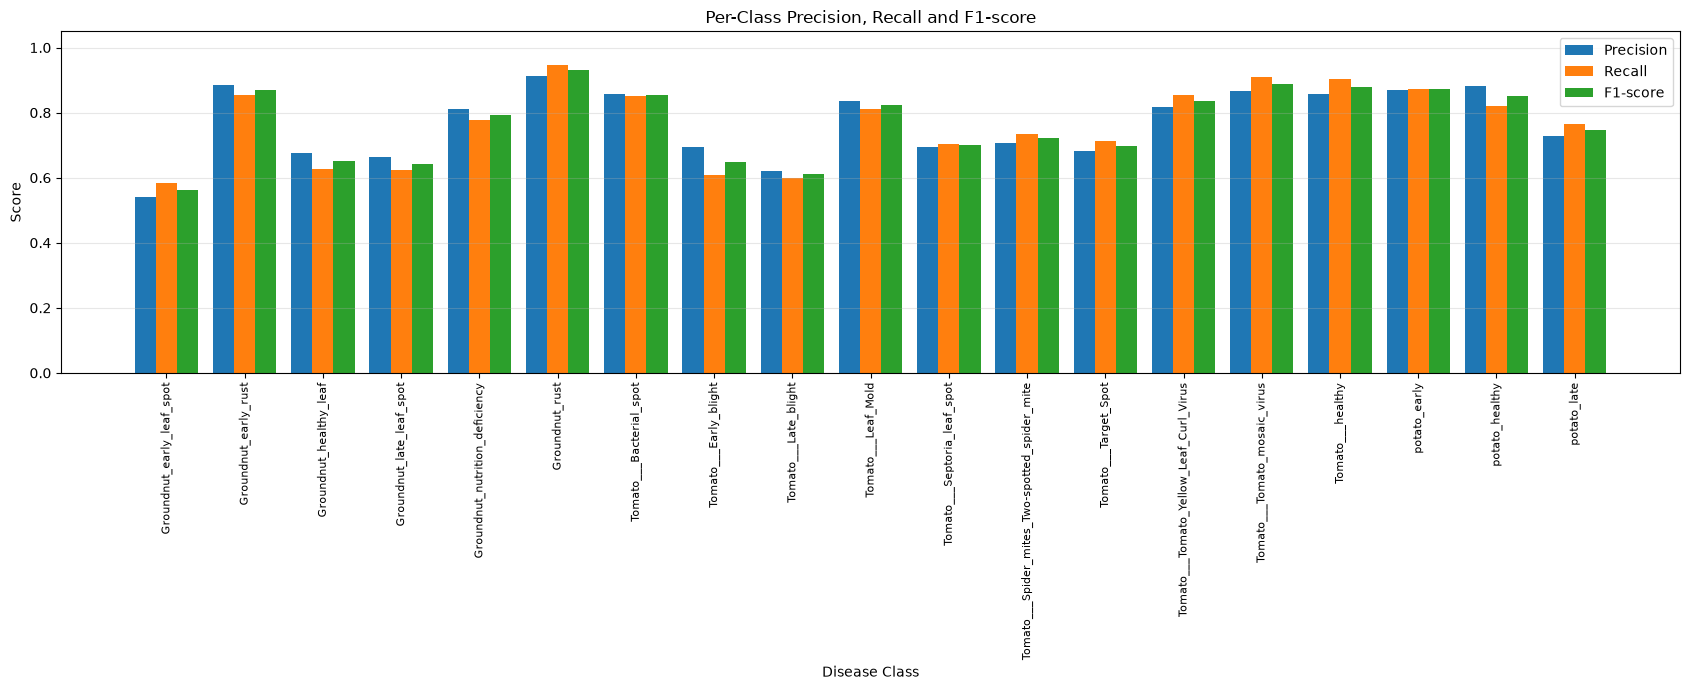

In [ ]:
# Compare precision, recall, and F1-score for each validation class.
report = classification_report(
    y_valid_combined,
    y_valid_pred_combined,
    labels=class_names,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

precision_values = [report[c]["precision"] for c in class_names]
recall_values = [report[c]["recall"] for c in class_names]
f1_values = [report[c]["f1-score"] for c in class_names]

x = np.arange(len(class_names))
width = 0.27

plt.figure(figsize=(17, 7))
plt.bar(x - width, precision_values, width, label="Precision")
plt.bar(x, recall_values, width, label="Recall")
plt.bar(x + width, f1_values, width, label="F1-score")

plt.title("Per-Class Precision, Recall and F1-score")
plt.xlabel("Disease Class")
plt.ylabel("Score")
plt.xticks(x, class_names, rotation=90, fontsize=8)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Random Forest Classification Using Combined Features


In [24]:
# Train and evaluate Random Forest using the combined HOG + HSV + LBP features.
# Reuse the existing imports, training data, and validation data.

rf_model = RandomForestClassifier(
    n_estimators=1000,       # Number of decision trees
    max_depth=50,           # Limit the depth of each tree
    min_samples_leaf=4,     # Require at least 2 samples in each leaf
    max_features="sqrt",    # Consider a subset of features at each split
    random_state=42,        # Make the experiment reproducible
    n_jobs=-1               # Use available CPU cores
)

# Train the model and measure the training time.
start_time = time.time()
rf_model.fit(X_train_combined, y_train_combined)
rf_training_seconds = time.time() - start_time

print(f"Training time: {rf_training_seconds / 60:.2f} minutes")

# Predict labels for the validation set.
start_time = time.time()
y_valid_pred_rf = rf_model.predict(X_valid_combined)
rf_prediction_seconds = time.time() - start_time

print(f"Validation prediction time: {rf_prediction_seconds:.2f} seconds")

# Calculate validation metrics.
print("\nRandom Forest — Validation Results")
print(f"Accuracy:        {accuracy_score(y_valid_combined, y_valid_pred_rf):.4f}")
print(f"Macro precision: {precision_score(y_valid_combined, y_valid_pred_rf, average='macro', zero_division=0):.4f}")
print(f"Macro recall:    {recall_score(y_valid_combined, y_valid_pred_rf, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score:  {f1_score(y_valid_combined, y_valid_pred_rf, average='macro', zero_division=0):.4f}")

# Display precision, recall, F1-score, and support for every class.
print("\nClassification Report:")
print(classification_report(
    y_valid_combined,
    y_valid_pred_rf,
    zero_division=0
))

Training time: 13.66 minutes
Validation prediction time: 2.72 seconds

Random Forest — Validation Results
Accuracy:        0.9405
Macro precision: 0.9380
Macro recall:    0.9348
Macro F1-score:  0.9360

Classification Report:
                                               precision    recall  f1-score   support

                    Groundnut_early_leaf_spot       0.84      0.76      0.80       185
                         Groundnut_early_rust       0.94      0.99      0.96       145
                       Groundnut_healthy_leaf       0.81      0.87      0.84       260
                     Groundnut_late_leaf_spot       0.88      0.87      0.87       236
               Groundnut_nutrition_deficiency       0.94      0.91      0.92       211
                               Groundnut_rust       0.98      0.98      0.98       191
                      Tomato___Bacterial_spot       0.94      0.92      0.93       346
                        Tomato___Early_blight       0.91      0.94      0.92 

In [25]:
# Save the already-trained Random Forest model.
# No retraining is performed in this cell.

from pathlib import Path

# Create the model directory if it does not already exist.
MODEL_DIR = Path("..") / "reports" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define the file path for the 1,000-tree Random Forest.
rf_model_path = MODEL_DIR / "random_forest_hog_hsv_lbp_1000_trees.joblib"

# Save the fitted model to disk.
joblib.dump(rf_model, rf_model_path)

print("Random Forest model saved successfully!")
print("Saved location:", rf_model_path.resolve())
print("Number of trees:", rf_model.n_estimators)
print("Maximum depth:", rf_model.max_depth)
print("Minimum samples per leaf:", rf_model.min_samples_leaf)

Random Forest model saved successfully!
Saved location: C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection\reports\models\random_forest_hog_hsv_lbp_1000_trees.joblib
Number of trees: 1000
Maximum depth: 50
Minimum samples per leaf: 4


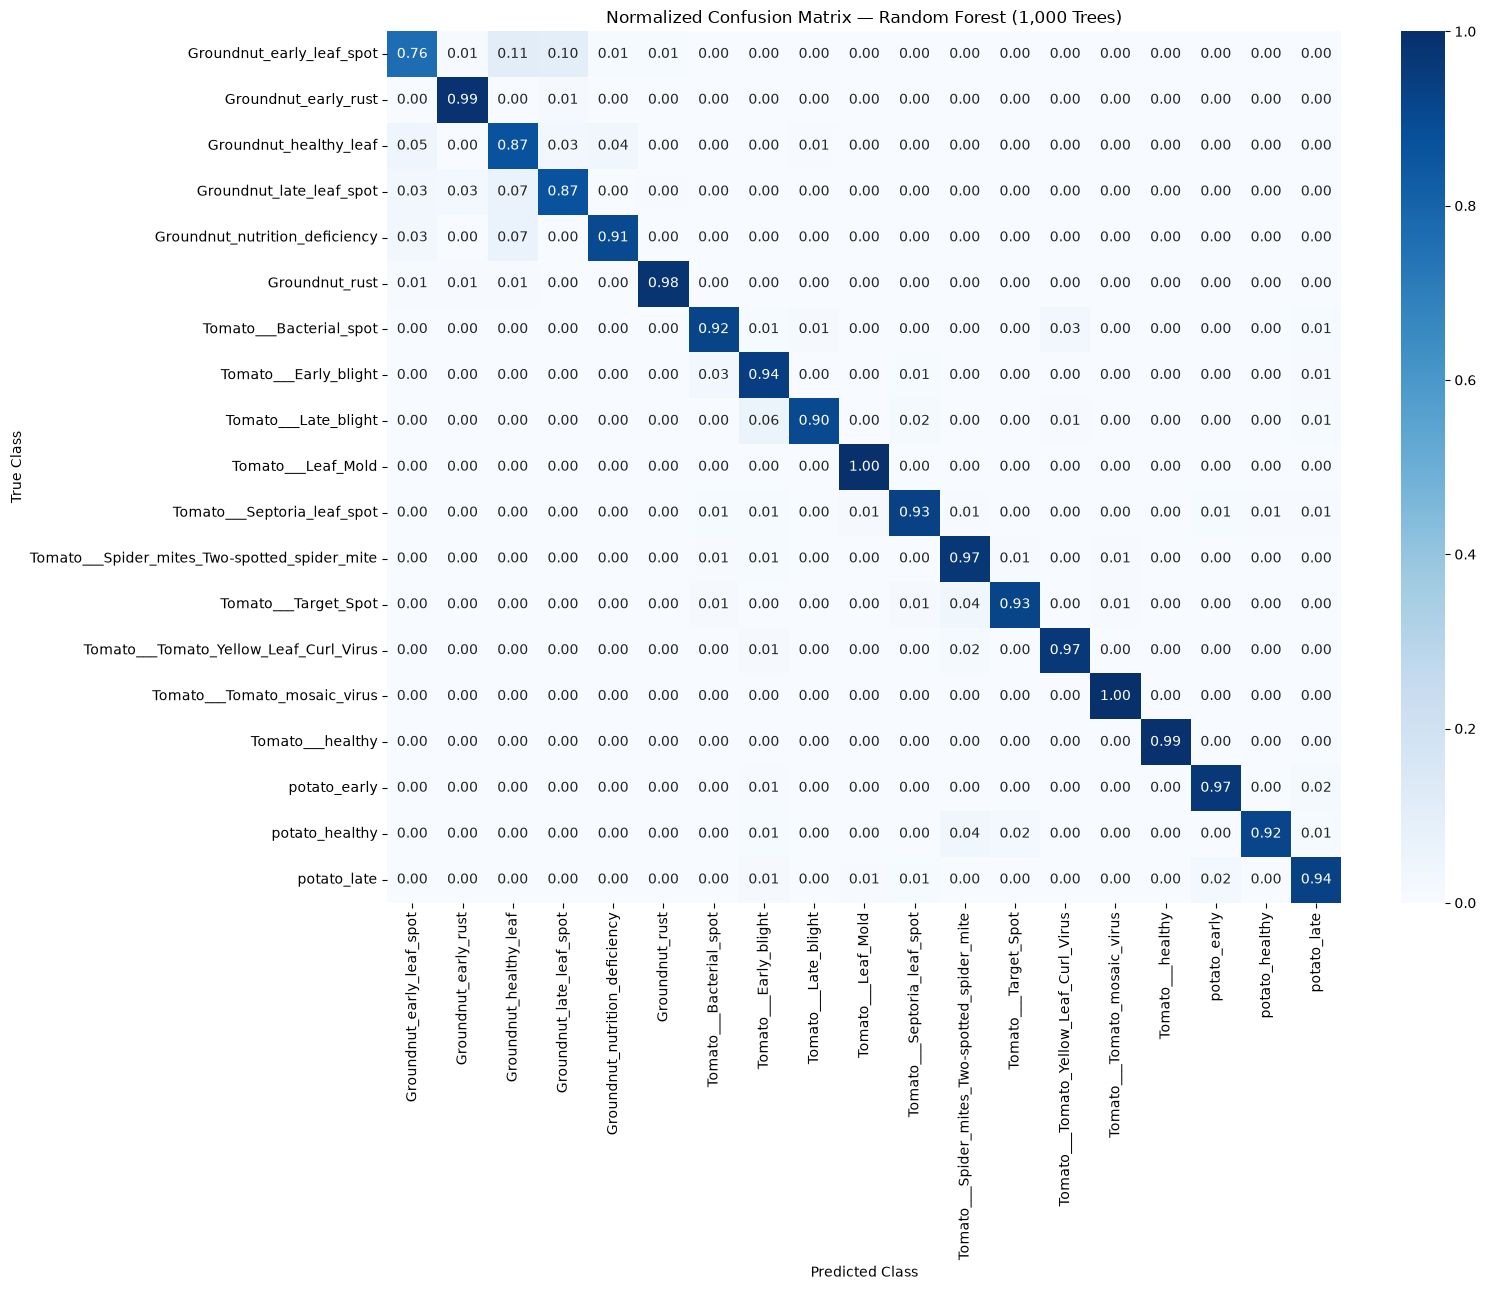

In [26]:
# Plot a row-normalized confusion matrix for the 1,000-tree Random Forest.
# Reuse the existing validation labels and predictions; do not retrain.
# Get class labels in a consistent order.
class_names = np.unique(y_valid_combined)

# Compute the confusion matrix and normalize each true-class row.
cm = confusion_matrix(
    y_valid_combined,
    y_valid_pred_rf,
    labels=class_names
)

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

# Plot the normalized matrix.
plt.figure(figsize=(16, 13))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix — Random Forest (1,000 Trees)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

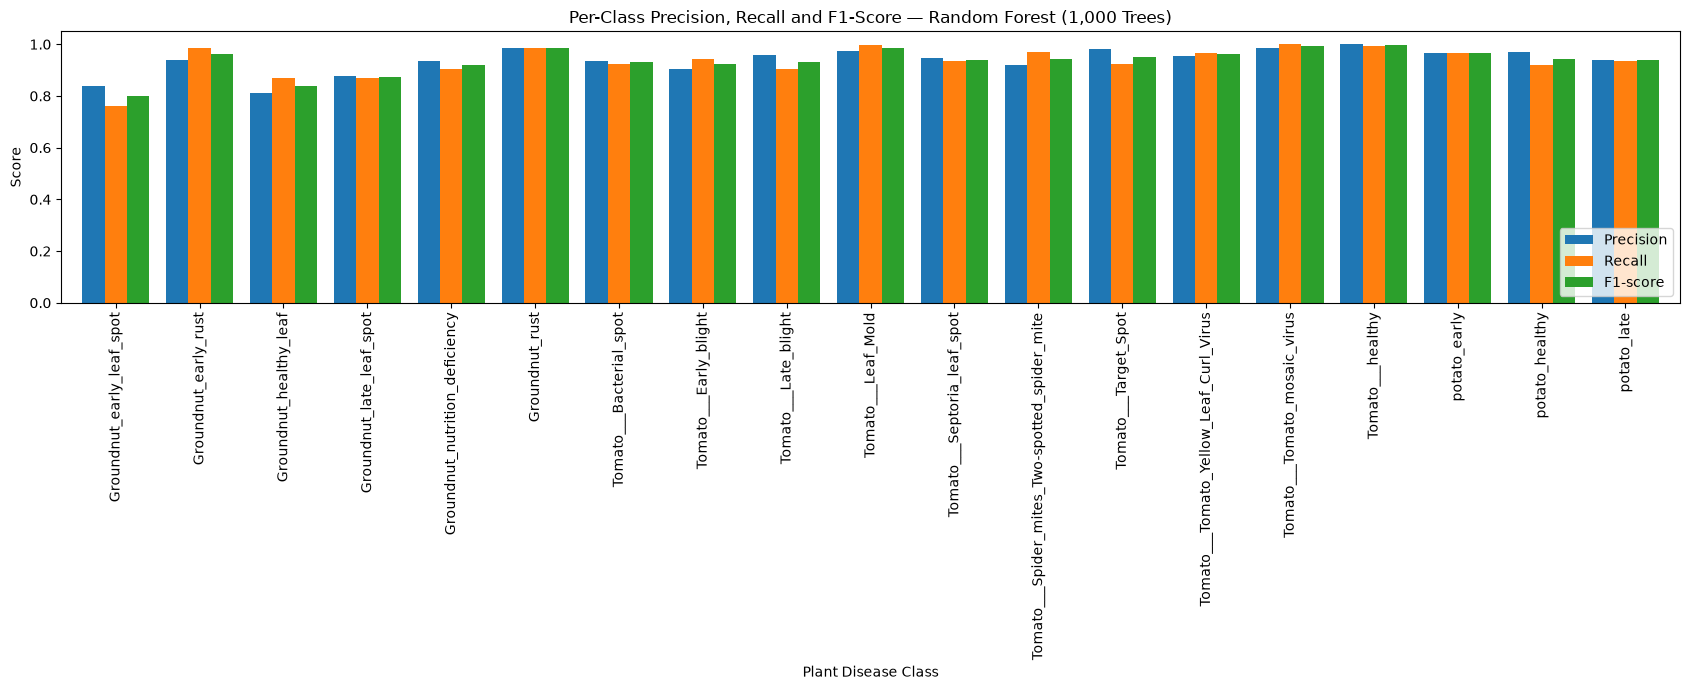

In [32]:
# Calculate and plot per-class precision, recall, and F1-score.
# Use the existing 1,000-tree Random Forest validation predictions.

from sklearn.metrics import precision_recall_fscore_support

# Calculate metrics separately for every class.
precision, recall, f1, support = precision_recall_fscore_support(
    y_valid_combined,
    y_valid_pred_rf,
    labels=class_names,
    zero_division=0
)

# Plot the three metrics for every class.
metrics_plot = rf_class_metrics.set_index("Class")[
    ["Precision", "Recall", "F1-score"]
]

metrics_plot.plot(
    kind="bar",
    figsize=(17, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Per-Class Precision, Recall and F1-Score — Random Forest (1,000 Trees)")
plt.xlabel("Plant Disease Class")
plt.ylabel("Score")
plt.xticks(rotation=90)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3. LightGBM Classification Using Combined Image Features

### Objective
Evaluate LightGBM for plant leaf disease classification using the combined HOG, HSV, and LBP features.

### Principle
LightGBM is a gradient-boosting algorithm that builds decision trees sequentially. Each new tree aims to improve the model by correcting errors from previous trees.

### Experimental methodology
1. Reuse the cached combined HOG, HSV, and LBP features.
2. Train LightGBM on the existing training split.
3. Evaluate predictions on the existing validation split.
4. Record accuracy, macro precision, macro recall, macro F1-score, training time, and prediction time.
5. Save the trained model for later comparison.

The test set remains reserved for final evaluation. No new feature extraction is required.

In [4]:
# Train and evaluate LightGBM using the existing combined features.
# Reuse the existing training/validation variables; do not retrain other models.

from lightgbm import LGBMClassifier

# Configure LightGBM for a manageable first experiment.
lgbm_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train and measure training time.
start_time = time.time()
lgbm_model.fit(X_train_combined, y_train_combined)
lgbm_training_seconds = time.time() - start_time

# Generate validation predictions.
start_time = time.time()
y_valid_pred_lgbm = lgbm_model.predict(X_valid_combined)
lgbm_prediction_seconds = time.time() - start_time

# Calculate key validation metrics without printing a long report.
lgbm_accuracy = accuracy_score(
    y_valid_combined, y_valid_pred_lgbm
)
lgbm_precision = precision_score(
    y_valid_combined, y_valid_pred_lgbm,
    average="macro", zero_division=0
)
lgbm_recall = recall_score(
    y_valid_combined, y_valid_pred_lgbm,
    average="macro", zero_division=0
)
lgbm_f1 = f1_score(
    y_valid_combined, y_valid_pred_lgbm,
    average="macro", zero_division=0
)

print("LightGBM — Validation Summary")
print(f"Training time:     {lgbm_training_seconds / 60:.2f} minutes")
print(f"Prediction time:   {lgbm_prediction_seconds:.2f} seconds")
print(f"Accuracy:          {lgbm_accuracy:.4f}")
print(f"Macro precision:   {lgbm_precision:.4f}")
print(f"Macro recall:      {lgbm_recall:.4f}")
print(f"Macro F1-score:    {lgbm_f1:.4f}")

# Save the fitted model for future comparison.
MODEL_DIR = PROJECT_ROOT / "reports" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

lgbm_model_path = MODEL_DIR / "lightgbm_hog_hsv_lbp.joblib"
joblib.dump(lgbm_model, lgbm_model_path)

print("\nSaved model:", lgbm_model_path)

LightGBM — Validation Summary
Training time:     59.58 minutes
Prediction time:   4.51 seconds
Accuracy:          0.9818
Macro precision:   0.9814
Macro recall:      0.9814
Macro F1-score:    0.9813

Saved model: C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection\reports\models\lightgbm_hog_hsv_lbp.joblib


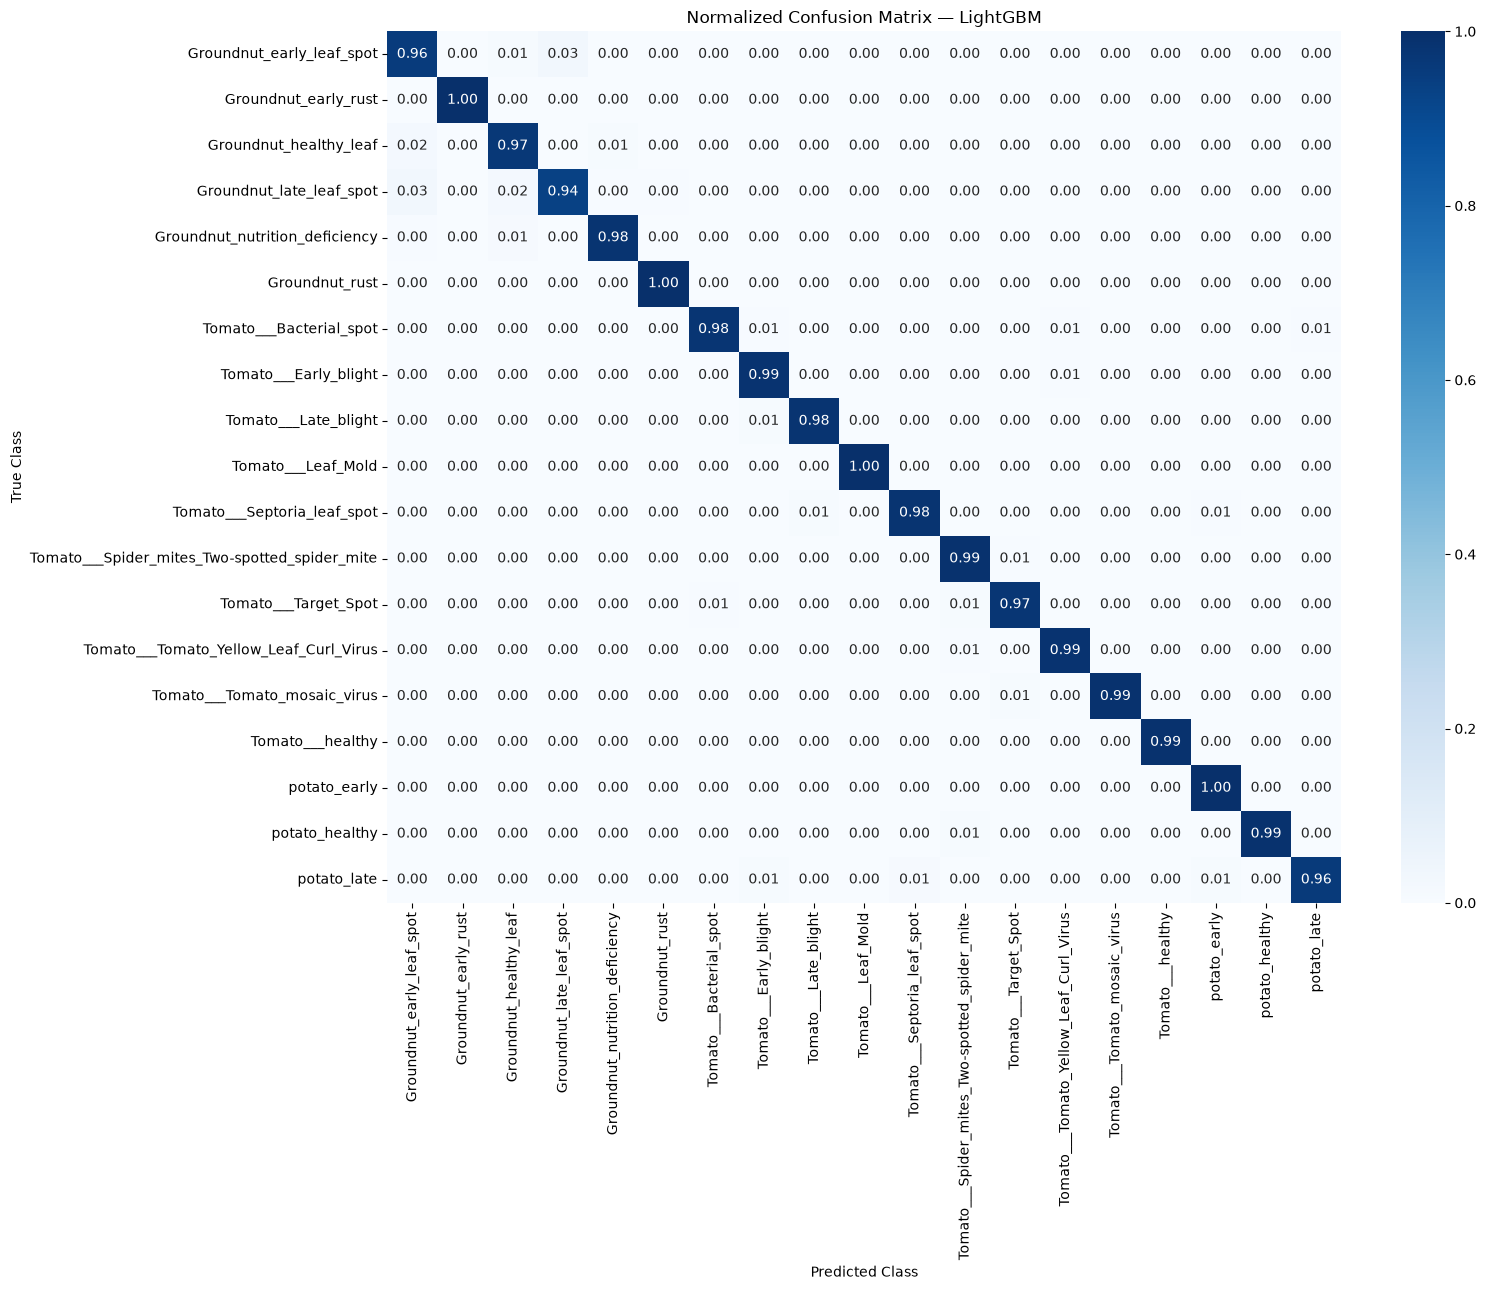

In [5]:
# Plot the normalized confusion matrix for the trained LightGBM model.
# Reuse existing validation predictions; no training is performed.

class_names = sorted(np.unique(y_valid_combined))

# Normalize each true-class row so values represent proportions.
cm_normalized_lgbm = confusion_matrix(
    y_valid_combined,
    y_valid_pred_lgbm,
    labels=class_names,
    normalize="true"
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm_normalized_lgbm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix — LightGBM")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

,Class,Precision,Recall,F1-score,Support
0,Groundnut_early_leaf_spot,0.9219,0.9568,0.9390,185
1,Groundnut_late_leaf_spot,0.9736,0.9364,0.9546,236
2,Groundnut_healthy_leaf,0.9617,0.9654,0.9635,260
3,potato_late,0.9782,0.9607,0.9694,280
4,Tomato___Target_Spot,0.9819,0.9731,0.9775,335
5,Tomato___Late_blight,0.9727,0.9828,0.9777,290
6,Tomato___Early_blight,0.9755,0.9862,0.9808,363
7,Groundnut_nutrition_deficiency,0.9810,0.9810,0.9810,211
8,Tomato___Septoria_leaf_spot,0.9821,0.9821,0.9821,335
9,Tomato___Bacterial_spot,0.9912,0.9769,0.9840,346


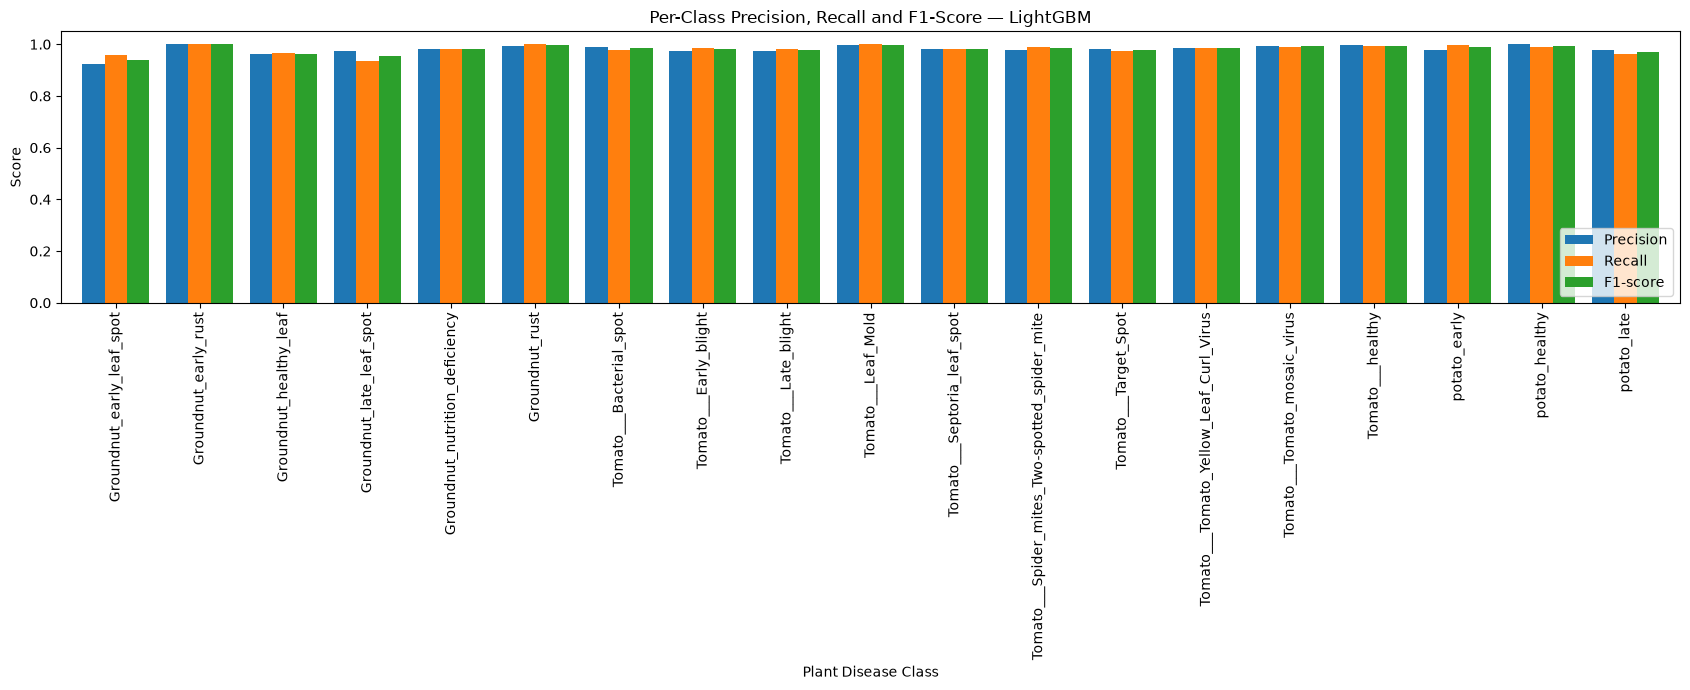

In [6]:
# Compare per-class precision, recall, and F1-score for LightGBM.
# Uses the existing normalized confusion matrix and validation labels.

# Get the raw confusion matrix for class counts.
cm_lgbm = confusion_matrix(
    y_valid_combined,
    y_valid_pred_lgbm,
    labels=class_names
)

# True positives are the diagonal entries.
true_positives = np.diag(cm_lgbm)

# Calculate support, predicted totals, precision, and recall.
support_lgbm = cm_lgbm.sum(axis=1)
predicted_totals = cm_lgbm.sum(axis=0)

recall_lgbm = np.divide(
    true_positives,
    support_lgbm,
    out=np.zeros_like(true_positives, dtype=float),
    where=support_lgbm != 0
)

precision_lgbm = np.divide(
    true_positives,
    predicted_totals,
    out=np.zeros_like(true_positives, dtype=float),
    where=predicted_totals != 0
)

# Calculate F1-score safely.
f1_lgbm = np.divide(
    2 * precision_lgbm * recall_lgbm,
    precision_lgbm + recall_lgbm,
    out=np.zeros_like(precision_lgbm, dtype=float),
    where=(precision_lgbm + recall_lgbm) != 0
)

# Create a per-class results table.
lgbm_class_metrics = pd.DataFrame({
    "Class": class_names,
    "Precision": precision_lgbm,
    "Recall": recall_lgbm,
    "F1-score": f1_lgbm,
    "Support": support_lgbm
})

# Display the lowest F1-score classes first.
display(
    lgbm_class_metrics
    .sort_values("F1-score")
    .round(4)
    .reset_index(drop=True)
)

# Plot all three metrics for every class.
metrics_plot_lgbm = lgbm_class_metrics.set_index("Class")[
    ["Precision", "Recall", "F1-score"]
]

metrics_plot_lgbm.plot(
    kind="bar",
    figsize=(17, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Per-Class Precision, Recall and F1-Score — LightGBM")
plt.xlabel("Plant Disease Class")
plt.ylabel("Score")
plt.xticks(rotation=90)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (min),Prediction Time (sec)
0,Linear SVM,0.7664,0.7688,0.7668,0.7673,23.86,0.12
1,Random Forest (1000 trees),0.9405,0.9380,0.9348,0.9360,13.66,2.72
2,LightGBM,0.9818,0.9814,0.9814,0.9813,59.58,4.51


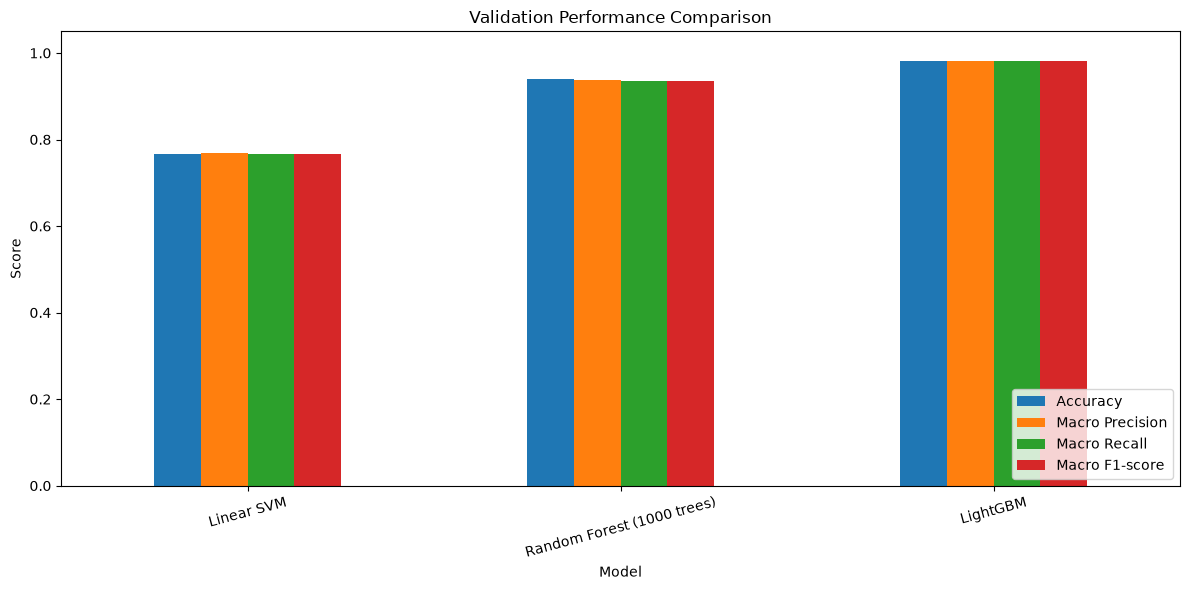

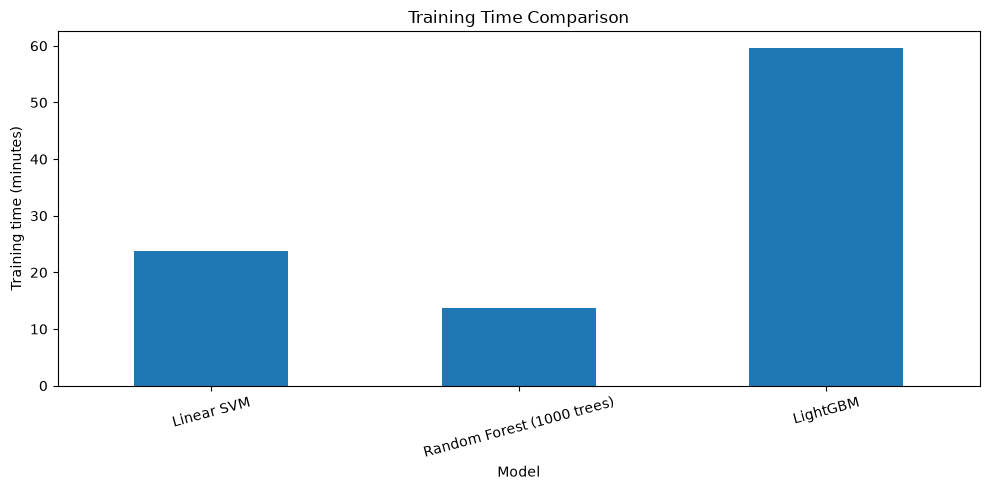

In [7]:
# Compare the three completed supervised learning experiments.
# Reuse existing validation predictions and previously recorded timings.

# Store each model's validation predictions.
model_predictions = {
    "Linear SVM": y_valid_pred_combined,
    "Random Forest (1000 trees)": y_valid_pred_rf,
    "LightGBM": y_valid_pred_lgbm
}

# Previously recorded training and prediction times.
training_times = {
    "Linear SVM": 23.86 * 60,
    "Random Forest (1000 trees)": 13.66 * 60,
    "LightGBM": 59.58 * 60
}

prediction_times = {
    "Linear SVM": 0.12,
    "Random Forest (1000 trees)": 2.72,
    "LightGBM": 4.51
}

# Calculate all metrics consistently from the same validation labels.
comparison_rows = []

for model_name, predictions in model_predictions.items():

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_valid_combined, predictions),
        "Macro Precision": precision_score(
            y_valid_combined, predictions,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_valid_combined, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_valid_combined, predictions,
            average="macro", zero_division=0
        ),
        "Training Time (min)": training_times[model_name] / 60,
        "Prediction Time (sec)": prediction_times[model_name]
    })

comparison_df = pd.DataFrame(comparison_rows)

# Display the comparison table.
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1-score": "{:.4f}",
        "Training Time (min)": "{:.2f}",
        "Prediction Time (sec)": "{:.2f}"
    })
)

# Chart 1: Compare classification metrics.
metric_columns = [
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"
]

comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Validation Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Chart 2: Compare training times.
comparison_df.set_index("Model")["Training Time (min)"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training Time Comparison")
plt.ylabel("Training time (minutes)")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Test Feature Extraction

Recreate the HOG, HSV and LBP test features using the original
feature-extraction functions from the supervised learning notebook.

Save the corrected features separately. Do not overwrite the
existing test caches or retrain any classifier.

In [33]:
# Reuse the imports, paths and settings already defined in the notebook.

from tqdm.auto import tqdm

# Verify required configuration.
assert test_dir.is_dir(), f"Test directory not found: {test_dir}"
assert IMAGE_SIZE == (128, 128)
assert HSV_BINS == (8, 8, 8)
assert LBP_BINS == 10

# Save corrected caches under new names.
# The previous test caches will remain untouched.
HOG_CORRECTED_PATH = HOG_DIR / "test_features_original_pipeline.npy"
HSV_CORRECTED_PATH = HSV_DIR / "test_features_original_pipeline.npy"
LBP_CORRECTED_PATH = LBP_DIR / "test_features_original_pipeline.npy"
LABELS_CORRECTED_PATH = HOG_DIR / "test_labels_original_pipeline.npy"

# Reproduce the original class and image ordering.
class_dirs = sorted(
    folder for folder in test_dir.iterdir()
    if folder.is_dir()
)

assert len(class_dirs) == 19, (
    f"Expected 19 classes, found {len(class_dirs)}."
)

test_image_paths = []

for class_dir in class_dirs:
    image_paths = sorted(
        path for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    test_image_paths.extend(image_paths)

assert len(test_image_paths) == 5273, (
    f"Expected 5273 test images, found {len(test_image_paths)}."
)

# Use the original extraction functions from the notebook.
hog_features_corrected = []
hsv_features_corrected = []
lbp_features_corrected = []
test_labels_corrected = []

for image_path in tqdm(
    test_image_paths,
    desc="Recreating original test features"
):
    # HOG: exact original Pillow-based extractor.
    hog_vector = extract_hog(image_path)

    # HSV: exact original OpenCV-based extractor.
    hsv_vector = extract_hsv_histogram(image_path)

    # LBP: exact original OpenCV-based extractor.
    lbp_vector = extract_lbp_histogram(image_path)

    hog_features_corrected.append(hog_vector)
    hsv_features_corrected.append(hsv_vector)
    lbp_features_corrected.append(lbp_vector)
    test_labels_corrected.append(image_path.parent.name)

# Convert to arrays.
X_test_hog_corrected = np.asarray(
    hog_features_corrected, dtype=np.float32
)
X_test_hsv_corrected = np.asarray(
    hsv_features_corrected, dtype=np.float32
)
X_test_lbp_corrected = np.asarray(
    lbp_features_corrected, dtype=np.float32
)
y_test_corrected = np.asarray(test_labels_corrected, dtype=str)

# Match the original combined feature order: HOG + HSV + LBP.
X_test_combined_corrected = np.concatenate(
    [
        X_test_hog_corrected,
        X_test_hsv_corrected,
        X_test_lbp_corrected
    ],
    axis=1
).astype(np.float32, copy=False)

# Verify dimensions, labels and finite values.
assert X_test_hog_corrected.shape == (5273, 8100)
assert X_test_hsv_corrected.shape == (5273, 512)
assert X_test_lbp_corrected.shape == (5273, 10)
assert X_test_combined_corrected.shape == (5273, 8622)

assert np.isfinite(X_test_combined_corrected).all()
assert len(np.unique(y_test_corrected)) == 19

# Save to separate files without overwriting the old caches.
np.save(HOG_CORRECTED_PATH, X_test_hog_corrected)
np.save(HSV_CORRECTED_PATH, X_test_hsv_corrected)
np.save(LBP_CORRECTED_PATH, X_test_lbp_corrected)
np.save(LABELS_CORRECTED_PATH, y_test_corrected)

print("\nCorrected test feature extraction complete.")
print("HOG:", X_test_hog_corrected.shape)
print("HSV:", X_test_hsv_corrected.shape)
print("LBP:", X_test_lbp_corrected.shape)
print("Combined:", X_test_combined_corrected.shape)
print("Labels:", y_test_corrected.shape)
print("Corrected caches saved separately.")

Recreating original test features: 100%|██████████| 5273/5273 [02:19<00:00, 37.85it/s]



Corrected test feature extraction complete.
HOG: (5273, 8100)
HSV: (5273, 512)
LBP: (5273, 10)
Combined: (5273, 8622)
Labels: (5273,)
Corrected caches saved separately.


## TESTing

In [44]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Predict with the existing trained model.
y_test_pred = lgbm_model.predict(X_test_corrected)

# Calculate metrics.
test_accuracy = accuracy_score(
    y_test_corrected,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test_corrected,
    y_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 55)
print("LIGHTGBM — CORRECTED TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Macro F1 : {test_macro_f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test_corrected,
        y_test_pred,
        zero_division=0
    )
)


LIGHTGBM — CORRECTED TEST RESULTS
Test Accuracy : 98.01%
Test Macro F1 : 97.90%

CLASSIFICATION REPORT
                                               precision    recall  f1-score   support

                    Groundnut_early_leaf_spot       0.96      0.92      0.94       166
                         Groundnut_early_rust       0.98      1.00      0.99       179
                       Groundnut_healthy_leaf       0.93      0.99      0.96       205
                     Groundnut_late_leaf_spot       0.97      0.92      0.94       236
               Groundnut_nutrition_deficiency       0.98      0.98      0.98       197
                               Groundnut_rust       1.00      1.00      1.00       217
                      Tomato___Bacterial_spot       0.99      0.97      0.98       314
                        Tomato___Early_blight       0.97      0.98      0.97       367
                         Tomato___Late_blight       0.98      0.97      0.98       389
                          

## LightGBM — Corrected Test Evaluation

The test set was evaluated using corrected HOG, HSV, and LBP features
generated with the original feature-extraction pipeline.

Test accuracy: 98.01%
Test macro F1-score: 97.90%



In [45]:
report_dict = classification_report(
    y_test_corrected,
    y_test_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

# Display all classes and metrics.
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 180
):
    display(report_df.round(4))

,precision,recall,f1-score,support
Groundnut_early_leaf_spot,0.9562,0.9217,0.9387,166.0000
Groundnut_early_rust,0.9781,1.0000,0.9890,179.0000
Groundnut_healthy_leaf,0.9309,0.9854,0.9573,205.0000
Groundnut_late_leaf_spot,0.9686,0.9153,0.9412,236.0000
Groundnut_nutrition_deficiency,0.9848,0.9848,0.9848,197.0000
Groundnut_rust,0.9954,1.0000,0.9977,217.0000
Tomato___Bacterial_spot,0.9902,0.9682,0.9791,314.0000
Tomato___Early_blight,0.9652,0.9837,0.9744,367.0000
Tomato___Late_blight,0.9844,0.9717,0.9780,389.0000
Tomato___Leaf_Mold,0.9970,1.0000,0.9985,336.0000


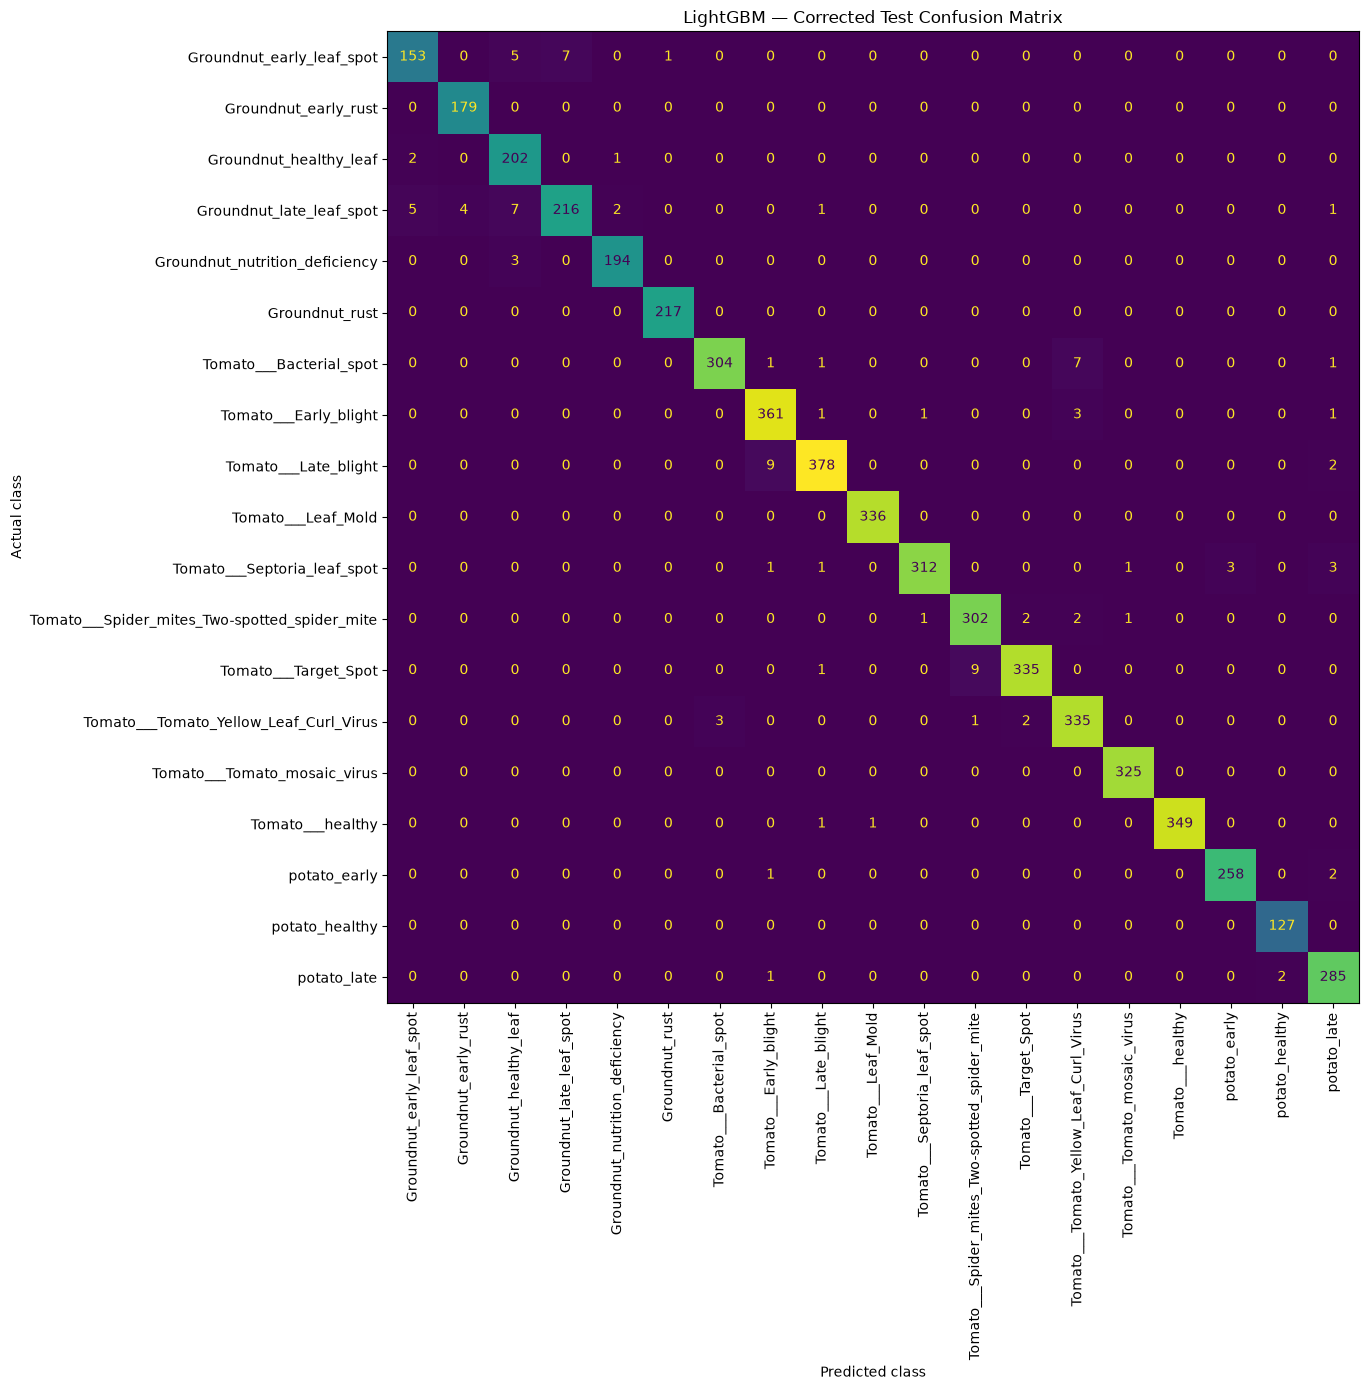

Confusion matrix shape: (19, 19)
Total test samples: 5273
Correct predictions: 5168
Incorrect predictions: 105


In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Use a consistent ordering of all 19 classes.
class_names = sorted(np.unique(y_test_corrected))

cm = confusion_matrix(
    y_test_corrected,
    y_test_pred,
    labels=class_names
)

# Display the confusion matrix.
fig, ax = plt.subplots(figsize=(16, 14))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

ax.set_title("LightGBM — Corrected Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

print("Confusion matrix shape:", cm.shape)
print("Total test samples:", cm.sum())
print("Correct predictions:", np.trace(cm))
print("Incorrect predictions:", cm.sum() - np.trace(cm))


In [58]:
# --------------------------------------------------
# 1. Define the results directory
# --------------------------------------------------
PROJECT_ROOT = Path(
    r"C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection"
)

RESULTS_DIR = PROJECT_ROOT / "results" / "supervised_learning" / "lightgbm"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Calculate final metrics from existing predictions
# --------------------------------------------------
y_true = np.asarray(y_test_corrected).astype(str)
y_pred = np.asarray(y_test_pred).astype(str)

assert len(y_true) == len(y_pred)
assert len(y_true) == 5273

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# --------------------------------------------------
# 3. Save summary metrics as JSON
# --------------------------------------------------
metrics = {
    "model": "LightGBM",
    "feature_extraction": "HOG + HSV + LBP",
    "feature_dimensions": 8622,
    "test_samples": int(len(y_true)),
    "number_of_classes": int(len(np.unique(y_true))),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "validation_accuracy_previous_result": 0.9818,
    "validation_macro_f1_previous_result": 0.9813,
    "test_misclassified_images": int(np.sum(y_true != y_pred))
}

with (RESULTS_DIR / "test_metrics.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

# Also save a simple CSV summary.
pd.DataFrame([metrics]).to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

# --------------------------------------------------
# 4. Save the complete classification report
# --------------------------------------------------
report = classification_report(
    y_true,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.to_csv(
    RESULTS_DIR / "classification_report.csv",
    index=True,
    index_label="class_or_average"
)

# --------------------------------------------------
# 5. Save the confusion matrix
# --------------------------------------------------
class_names = sorted(np.unique(y_true))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.index.name = "Actual"
cm_df.columns.name = "Predicted"

cm_df.to_csv(RESULTS_DIR / "confusion_matrix.csv")

# --------------------------------------------------
# 6. Save individual test predictions
# --------------------------------------------------
predictions_df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred,
    "Correct": y_true == y_pred
})

predictions_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

# --------------------------------------------------
# 7. Confirm saved files
# --------------------------------------------------
print("LightGBM results saved successfully.")
print(f"\nResults directory: {RESULTS_DIR}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test macro F1: {test_macro_f1 * 100:.2f}%")
print(f"Test weighted F1: {test_weighted_f1 * 100:.2f}%")
print(f"Misclassified images: {np.sum(y_true != y_pred)}")

print("\nFiles created:")
for file_path in sorted(RESULTS_DIR.iterdir()):
    print(f" - {file_path.name}")


LightGBM results saved successfully.

Results directory: C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection\results\supervised_learning\lightgbm
Test accuracy: 98.01%
Test macro F1: 97.90%
Test weighted F1: 98.00%
Misclassified images: 105

Files created:
 - classification_report.csv
 - confusion_matrix.csv
 - test_metrics.csv
 - test_metrics.json
 - test_predictions.csv


## PROJECT RECOVERY CELL
## Restore cached features, saved SVM, validation predictions,
## metrics, and variables for graphs — WITHOUT retraining.

In [61]:

# ============================================================
# 1. Imports and project paths
# ============================================================
from pathlib import Path
import numpy as np
import joblib
import json
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = Path(
    r"C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection"
)

assert PROJECT_ROOT.exists(), f"Project folder not found: {PROJECT_ROOT}"

DATASET_ROOT = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced"
)

train_dir = DATASET_ROOT / "train"
valid_dir = DATASET_ROOT / "valid"
test_dir = DATASET_ROOT / "test"

# ============================================================
# 2. Feature cache paths
# ============================================================
HOG_DIR = PROJECT_ROOT / "data" / "hog_cache"
HSV_DIR = PROJECT_ROOT / "data" / "hsv_cache"
LBP_DIR = PROJECT_ROOT / "data" / "lbp_cache"

def load_feature_cache(cache_dir, split):
    """Load cached features and labels for a dataset split."""
    feature_file = cache_dir / f"{split}_features.npy"
    label_file = cache_dir / f"{split}_labels.npy"

    if not feature_file.exists() or not label_file.exists():
        raise FileNotFoundError(
            f"Missing cache files in {cache_dir} for split '{split}'."
        )

    features = np.load(feature_file, mmap_mode="r")
    labels = np.load(label_file, allow_pickle=True)

    return features, labels

# ============================================================
# 3. Load HOG features: train and validation
# ============================================================
X_train_hog, y_train_hog = load_feature_cache(HOG_DIR, "train")
X_valid_hog, y_valid_hog = load_feature_cache(HOG_DIR, "valid")

# ============================================================
# 4. Load HSV features: train and validation
# ============================================================
X_train_hsv, y_train_hsv = load_feature_cache(HSV_DIR, "train")
X_valid_hsv, y_valid_hsv = load_feature_cache(HSV_DIR, "valid")

# ============================================================
# 5. Load LBP features: train and validation
# ============================================================
X_train_lbp, y_train_lbp = load_feature_cache(LBP_DIR, "train")
X_valid_lbp, y_valid_lbp = load_feature_cache(LBP_DIR, "valid")

# ============================================================
# 6. Check feature and label alignment
# ============================================================
assert np.array_equal(y_train_hog, y_train_hsv), \
    "Training HSV labels mismatch."

assert np.array_equal(y_train_hog, y_train_lbp), \
    "Training LBP labels mismatch."

assert np.array_equal(y_valid_hog, y_valid_hsv), \
    "Validation HSV labels mismatch."

assert np.array_equal(y_valid_hog, y_valid_lbp), \
    "Validation LBP labels mismatch."

assert X_train_hog.shape[0] == X_train_hsv.shape[0] == X_train_lbp.shape[0]
assert X_valid_hog.shape[0] == X_valid_hsv.shape[0] == X_valid_lbp.shape[0]

# ============================================================
# 7. Combine HOG + HSV + LBP features
# ============================================================
X_train_combined = np.concatenate(
    [X_train_hog, X_train_hsv, X_train_lbp], axis=1
).astype(np.float32, copy=False)

X_valid_combined = np.concatenate(
    [X_valid_hog, X_valid_hsv, X_valid_lbp], axis=1
).astype(np.float32, copy=False)

y_train_combined = y_train_hog
y_valid_combined = y_valid_hog

print("HOG train:", X_train_hog.shape)
print("HSV train:", X_train_hsv.shape)
print("LBP train:", X_train_lbp.shape)
print("Combined train:", X_train_combined.shape)
print("Combined validation:", X_valid_combined.shape)

# ============================================================
# 8. Load saved Linear SVM model
# ============================================================
SVM_MODEL_PATH = (
    PROJECT_ROOT / "reports" / "models"
    / "linear_svm_hog_hsv_lbp.joblib"
)

if not SVM_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved SVM model not found: {SVM_MODEL_PATH}"
    )

combined_svm = joblib.load(SVM_MODEL_PATH)

# ============================================================
# 9. Load saved 1,000-tree Random Forest model
# ============================================================
RF_MODEL_PATH = (
    PROJECT_ROOT / "reports" / "models"
    / "random_forest_hog_hsv_lbp_1000_trees.joblib"
)

if not RF_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved Random Forest model not found: {RF_MODEL_PATH}"
    )

rf_model = joblib.load(RF_MODEL_PATH)

# ============================================================
# 10. Load saved LightGBM model
# ============================================================
LGBM_MODEL_PATH = (
    PROJECT_ROOT / "reports" / "models"
    / "lightgbm_hog_hsv_lbp.joblib"
)

if not LGBM_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved LightGBM model not found: {LGBM_MODEL_PATH}"
    )

lgbm_model = joblib.load(LGBM_MODEL_PATH)

# ============================================================
# 11. Generate validation predictions (no training)
# ============================================================
y_valid_pred_combined = combined_svm.predict(X_valid_combined)
y_valid_pred_rf = rf_model.predict(X_valid_combined)
y_valid_pred_lgbm = lgbm_model.predict(X_valid_combined)

# ============================================================
# 12. Restore validation confusion matrices
# ============================================================
class_names = sorted(np.unique(y_valid_combined))

# Linear SVM
cm_svm = confusion_matrix(
    y_valid_combined, y_valid_pred_combined, labels=class_names
)
cm_normalized_svm = confusion_matrix(
    y_valid_combined, y_valid_pred_combined,
    labels=class_names, normalize="true"
)

# Random Forest
cm_rf = confusion_matrix(
    y_valid_combined, y_valid_pred_rf, labels=class_names
)
cm_normalized_rf = confusion_matrix(
    y_valid_combined, y_valid_pred_rf,
    labels=class_names, normalize="true"
)

# LightGBM
cm_lgbm_valid = confusion_matrix(
    y_valid_combined, y_valid_pred_lgbm, labels=class_names
)
cm_normalized_lgbm_valid = confusion_matrix(
    y_valid_combined, y_valid_pred_lgbm,
    labels=class_names, normalize="true"
)

# ============================================================
# 13. Load corrected ORIGINAL-PIPELINE test features
#     These are the corrected files created previously.
# ============================================================
HOG_TEST_FILE = HOG_DIR / "test_features_original_pipeline.npy"
HSV_TEST_FILE = HSV_DIR / "test_features_original_pipeline.npy"
LBP_TEST_FILE = LBP_DIR / "test_features_original_pipeline.npy"
TEST_LABEL_FILE = HOG_DIR / "test_labels_original_pipeline.npy"

required_test_files = [
    HOG_TEST_FILE,
    HSV_TEST_FILE,
    LBP_TEST_FILE,
    TEST_LABEL_FILE
]

for file_path in required_test_files:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Required corrected test file not found: {file_path}"
        )

X_test_hog_corrected = np.load(HOG_TEST_FILE, mmap_mode="r")
X_test_hsv_corrected = np.load(HSV_TEST_FILE, mmap_mode="r")
X_test_lbp_corrected = np.load(LBP_TEST_FILE, mmap_mode="r")
y_test_corrected = np.load(TEST_LABEL_FILE, allow_pickle=True)

# Check row counts and dimensions before combining
assert X_test_hog_corrected.shape[0] == len(y_test_corrected)
assert X_test_hsv_corrected.shape[0] == len(y_test_corrected)
assert X_test_lbp_corrected.shape[0] == len(y_test_corrected)

assert X_test_hog_corrected.shape[1] == X_train_hog.shape[1], \
    "HOG test feature dimension does not match training."

assert X_test_hsv_corrected.shape[1] == X_train_hsv.shape[1], \
    "HSV test feature dimension does not match training."

assert X_test_lbp_corrected.shape[1] == X_train_lbp.shape[1], \
    "LBP test feature dimension does not match training."

# ============================================================
# 14. Combine corrected test features
# ============================================================
X_test_corrected = np.concatenate(
    [
        X_test_hog_corrected,
        X_test_hsv_corrected,
        X_test_lbp_corrected
    ],
    axis=1
).astype(np.float32, copy=False)

print("\nCorrected test feature shapes:")
print("HOG:", X_test_hog_corrected.shape)
print("HSV:", X_test_hsv_corrected.shape)
print("LBP:", X_test_lbp_corrected.shape)
print("Combined test:", X_test_corrected.shape)
print("Test labels:", y_test_corrected.shape)

# ============================================================
# 15. Check LightGBM compatibility before test evaluation
# ============================================================
expected_features = getattr(lgbm_model, "n_features_in_", None)

if expected_features is None and hasattr(lgbm_model, "booster_"):
    expected_features = lgbm_model.booster_.num_feature()

if expected_features is not None:
    assert X_test_corrected.shape[1] == expected_features, (
        f"LightGBM expects {expected_features} features, "
        f"but test data has {X_test_corrected.shape[1]}."
    )

assert set(np.unique(y_test_corrected)) == set(class_names), \
    "Test classes do not match the validation classes."

# ============================================================
# 16. Final LightGBM test predictions (no training)
# ============================================================
y_test_pred_lgbm = lgbm_model.predict(X_test_corrected)

# ============================================================
# 17. Calculate final test metrics
# ============================================================
test_accuracy = accuracy_score(
    y_test_corrected, y_test_pred_lgbm
)

test_macro_f1 = f1_score(
    y_test_corrected, y_test_pred_lgbm,
    average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    y_test_corrected, y_test_pred_lgbm,
    average="weighted", zero_division=0
)

test_report = classification_report(
    y_test_corrected,
    y_test_pred_lgbm,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

cm_lgbm_test = confusion_matrix(
    y_test_corrected,
    y_test_pred_lgbm,
    labels=class_names
)

cm_normalized_lgbm_test = confusion_matrix(
    y_test_corrected,
    y_test_pred_lgbm,
    labels=class_names,
    normalize="true"
)

test_errors = int(np.sum(y_test_corrected != y_test_pred_lgbm))

print("\n========== FINAL LIGHTGBM TEST RESULTS ==========")
print(f"Test accuracy : {test_accuracy:.4%}")
print(f"Macro F1-score: {test_macro_f1:.4%}")
print(f"Weighted F1   : {test_weighted_f1:.4%}")
print(f"Test samples  : {len(y_test_corrected)}")
print(f"Errors        : {test_errors}")

# ============================================================
# 18. Save LightGBM validation and test evaluation artifacts
# ============================================================
RESULTS_DIR = PROJECT_ROOT / "results" / "supervised_learning" / "lightgbm"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Validation confusion matrices
pd.DataFrame(
    cm_lgbm_valid, index=class_names, columns=class_names
).to_csv(RESULTS_DIR / "validation_confusion_matrix.csv")

pd.DataFrame(
    cm_normalized_lgbm_valid,
    index=class_names, columns=class_names
).to_csv(RESULTS_DIR / "validation_confusion_matrix_normalized.csv")

# Test classification report and confusion matrices
pd.DataFrame(test_report).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

pd.DataFrame(
    cm_lgbm_test, index=class_names, columns=class_names
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

pd.DataFrame(
    cm_normalized_lgbm_test,
    index=class_names, columns=class_names
).to_csv(RESULTS_DIR / "confusion_matrix_normalized.csv")

# Test predictions
pd.DataFrame({
    "actual_label": y_test_corrected,
    "predicted_label": y_test_pred_lgbm,
    "correct": y_test_corrected == y_test_pred_lgbm
}).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

# Test metrics
test_metrics = {
    "model": "LightGBM",
    "feature_extraction": "HOG + HSV + LBP",
    "feature_dimensions": int(X_test_corrected.shape[1]),
    "test_samples": int(len(y_test_corrected)),
    "number_of_classes": int(len(class_names)),
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1),
    "weighted_f1": float(test_weighted_f1),
    "errors": test_errors
}

with open(RESULTS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=4)

pd.DataFrame([test_metrics]).to_csv(
    RESULTS_DIR / "test_metrics.csv", index=False
)

# ============================================================
# 19. Recovery and evaluation confirmation
# ============================================================
print("\nRecovery and evaluation complete.")
print("Combined train:", X_train_combined.shape)
print("Combined validation:", X_valid_combined.shape)
print("Combined corrected test:", X_test_corrected.shape)
print("Linear SVM loaded:", SVM_MODEL_PATH.name)
print("Random Forest loaded:", RF_MODEL_PATH.name)
print("Random Forest trees:", rf_model.n_estimators)
print("LightGBM loaded:", LGBM_MODEL_PATH.name)
print("Validation predictions and confusion matrices are ready.")
print("Final LightGBM test evaluation is complete.")
print("Test results saved to:", RESULTS_DIR)
print("No model training was performed.")
print("Only LightGBM was evaluated on the test set.")


HOG train: (24630, 8100)
HSV train: (24630, 512)
LBP train: (24630, 10)
Combined train: (24630, 8622)
Combined validation: (5278, 8622)

Corrected test feature shapes:
HOG: (5273, 8100)
HSV: (5273, 512)
LBP: (5273, 10)
Combined test: (5273, 8622)
Test labels: (5273,)

========== FINAL LIGHTGBM TEST RESULTS ==========
Test accuracy : 98.0087%
Macro F1-score: 97.9013%
Weighted F1   : 98.0043%
Test samples  : 5273
Errors        : 105

Recovery and evaluation complete.
Combined train: (24630, 8622)
Combined validation: (5278, 8622)
Combined corrected test: (5273, 8622)
Linear SVM loaded: linear_svm_hog_hsv_lbp.joblib
Random Forest loaded: random_forest_hog_hsv_lbp_1000_trees.joblib
Random Forest trees: 1000
LightGBM loaded: lightgbm_hog_hsv_lbp.joblib
Validation predictions and confusion matrices are ready.
Final LightGBM test evaluation is complete.
Test results saved to: C:\Intro_TO_AI_Project\Multi_Plant_Leaf_Disease_Detection\results\supervised_learning\lightgbm
No model training was p